# Task 2 — Corruption Classification and Hard-Routed Specialist Autoencoders
**Colab notebook, Google Drive-backed.** Every artifact (dataset cache, manifests, checkpoints, results, ONNX exports) lives under one Drive folder (`task2_artifacts_correct/`), so progress survives disconnects automatically — just re-run the notebook and it resumes from the last saved checkpoint, no manual save step needed.

**What changed from the version you had before, and why:** the previous autoencoder (`CorruptionRemoverAE`) used `ConvTranspose2d` upsampling (documented source of checkerboard/blur artifacts) and was trained with **pure MSE loss** — SSIM was only being logged, never actually optimized. MSE is well known to produce *more* blur than L1, since squaring the error pushes the optimum harder toward a pixel-wise average. That combination is what produced the uniform, input-independent smoothing you were seeing. This notebook uses `SpecialistAutoencoder`: a genuine spatial bottleneck, resize-convolution upsampling (nearest + conv, no checkerboard artifacts), a real L1+SSIM combined loss, and — specifically to counter pixel-loss blur further — a **Sobel edge loss** for the blur specialist and a **VGG perceptual loss** for the occlusion specialist. It also fixes a validation-set bug: each specialist previously validated on only ~5% of the dataset (a random quarter of the val split), which made early stopping fire before real convergence; each specialist now gets a dedicated manifest covering the full val split.

**Debugging tools built in, and fixed in this version:** `overfit_sanity_check()` — the definitive test for whether a "still blurry" result is an architecture bug or a training-budget issue. This was previously miscalibrated (tested at 32–64px, never verified at this notebook's actual 128×128 resolution) and could report a false "real bug" alarm when the truth was just "needs more steps at this resolution" — it's now trend-aware (distinguishes *plateaued* from *still improving*) with a resolution-appropriate step budget. `output_diversity_check()` — catches mean-collapse (a model that ignores its input and always predicts roughly the same image); this was being called *before* checkpoint resume, so it was measuring a freshly-initialized random model and misreporting mean-collapse on perfectly healthy resumed specialists — now runs after resume, and again every 10 epochs during training so you can watch input-responsiveness develop over a run instead of only checking once. `save_qualitative_snapshot()` — a before/after image grid every 5 epochs, so you can *see* sharpening happen rather than only reading loss numbers.

**Training budget increased.** Earlier runs showed the salt-and-pepper specialist still improving right at the old 60-epoch ceiling, and blur/occlusion exhausting the old patience=12 right around epoch 53 — both signs of training being cut off before real convergence, not a capacity problem. Ceiling raised to 200 epochs, patience to 25.

**The last section** reloads the classifier and all three specialists strictly from their saved Drive checkpoints (not whatever happens to be in memory) and runs the complete hard-routed pipeline end to end — this is the real test of whether everything actually works from a fresh state, and it doubles as a preview of the Hard-Routed Restoration app's display (probabilities, predicted class, selected expert, restored image, inference time).

## 1. Install dependencies

In [ ]:
# Colab already has torch, torchvision, opencv, pandas, matplotlib,
# scikit-learn, tqdm. Only these are missing:
!pip install -q optuna pytorch-msssim onnx onnxruntime mlflow


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 3.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 2.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 15.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 55.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.6/23.6 MB 50.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 35.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 59.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 64.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 15.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 7.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.

## 2. Mount Drive, paths, checkpoint helpers

In [ ]:
import os, glob, json, random, time, math, shutil
import numpy as np
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets
from PIL import Image
import matplotlib.pyplot as plt
from pytorch_msssim import ssim as ssim_metric
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                              confusion_matrix, classification_report)

# ============================================================
# Colab + Google Drive paths
#
# Everything lives under one Drive folder. Because Drive persists across
# Colab sessions (unlike Kaggle's /kaggle/working), checkpoints, manifests,
# and results survive a disconnect/reconnect automatically -- no "commit"
# step needed, just re-run the notebook and it picks up where it left off.
#
#   task2_artifacts_correct/
#     oxford_pet_raw/       <- dataset (downloaded once)
#     manifests/            <- val/test manifests + per-specialist val manifests
#     checkpoints/          <- *_best.pt, *_last.pt
#     results/              <- metrics, plots, optuna json, snapshots/
#     onnx_export/          <- exported models
#     data_split.json       <- train/val/test path lists
# ============================================================

from google.colab import drive
drive.mount('/content/drive', force_remount=False)

DRIVE_BASE = '/content/drive/MyDrive/task2_artifacts_correct'
os.makedirs(DRIVE_BASE, exist_ok=True)

DATA_ROOT = os.path.join(DRIVE_BASE, 'oxford_pet_raw')
MANIFEST_DIR = os.path.join(DRIVE_BASE, 'manifests')
CKPT_DIR = os.path.join(DRIVE_BASE, 'checkpoints')
RESULTS_DIR = os.path.join(DRIVE_BASE, 'results')
ONNX_DIR = os.path.join(DRIVE_BASE, 'onnx_export')

for d in [DATA_ROOT, MANIFEST_DIR, CKPT_DIR, RESULTS_DIR, ONNX_DIR]:
    os.makedirs(d, exist_ok=True)

assert os.path.isdir('/content/drive/MyDrive'), \
    "Google Drive is not mounted. Run drive.mount() and approve the prompt."
print('Drive base:', DRIVE_BASE)

SEED = 42
IMG_SIZE = 128


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', DEVICE)


def find_file(filename, subdir='checkpoints'):
    """Drive persists everything, so this just looks in the one Drive
    folder -- no session-vs-attached-dataset distinction needed (that
    complexity was specific to Kaggle)."""
    path = os.path.join(DRIVE_BASE, subdir, filename)
    return path if os.path.exists(path) else None


def save_checkpoint(state, filename, subdir='checkpoints'):
    """Atomic save (write to .tmp then rename) so a checkpoint is never
    left half-written if the session disconnects mid-save."""
    d = os.path.join(DRIVE_BASE, subdir)
    os.makedirs(d, exist_ok=True)
    path = os.path.join(d, filename)
    tmp_path = path + '.tmp'
    torch.save(state, tmp_path)
    os.replace(tmp_path, path)
    return path


def verify_checkpoint(filename, subdir='checkpoints', required_keys=('model_state',)):
    """Reloads a just-saved checkpoint and confirms it's intact -- cheap
    insurance against Drive sync hiccups corrupting a save silently."""
    path = find_file(filename, subdir)
    if path is None:
        print(f'verify_checkpoint: {filename} not found.')
        return False
    try:
        ckpt = torch.load(path, map_location='cpu')
    except Exception as e:
        print(f'verify_checkpoint: {filename} FAILED TO LOAD ({e}) -- the save may be corrupted.')
        return False
    missing = [k for k in required_keys if k not in ckpt]
    if missing:
        print(f'verify_checkpoint: {filename} is missing keys {missing}.')
        return False
    print(f'verify_checkpoint: {filename} OK ({path}, {os.path.getsize(path)/1e6:.1f} MB)')
    return True


def load_json_if_exists(filename, subdir=''):
    path = os.path.join(DRIVE_BASE, subdir, filename) if subdir else os.path.join(DRIVE_BASE, filename)
    if os.path.exists(path):
        with open(path) as f:
            return json.load(f), path
    return None, None


Mounted at /content/drive
Drive base: /content/drive/MyDrive/task2_artifacts_correct
Using device: cuda


## 3. Dataset download + 80/20 split (reused from Drive if present)

In [ ]:
# Reuses the exact same split as Task 1 if data_split.json is found on
# Drive. Otherwise regenerates it -- with the same seed=42 and the same
# torchvision dataset ordering, this reproduces the identical split.

trainval_raw = datasets.OxfordIIITPet(root=DATA_ROOT, split='trainval', target_types='category', download=True)
test_raw = datasets.OxfordIIITPet(root=DATA_ROOT, split='test', target_types='category', download=True)
print('Official trainval (development) size:', len(trainval_raw))
print('Official test size (untouched until final eval):', len(test_raw))

trainval_paths = [str(p) for p in trainval_raw._images]
test_paths_all = [str(p) for p in test_raw._images]


def paths_look_valid(manifest_or_paths):
    """A data_split.json (or manifest) saved from a different environment
    (e.g. an old Kaggle run) would have paths starting with /kaggle/... --
    catch that instead of silently trying to load images that don't exist
    here."""
    if not manifest_or_paths:
        return False
    sample = manifest_or_paths[0]
    sample_path = sample['path'] if isinstance(sample, dict) else sample
    return os.path.exists(sample_path)


split_record, split_source = load_json_if_exists('data_split.json')
if split_record is not None and paths_look_valid(split_record['train']):
    train_paths, val_paths, test_paths = split_record['train'], split_record['val'], split_record['test']
    print(f'Reusing existing split from {split_source}')
else:
    if split_record is not None:
        print('Existing data_split.json has paths that don\'t exist here (from a different '
              'environment?) -- regenerating.')
    rng = np.random.default_rng(SEED)
    indices = np.arange(len(trainval_paths))
    rng.shuffle(indices)
    split_point = int(0.8 * len(indices))
    train_idx, val_idx = indices[:split_point], indices[split_point:]
    train_paths = [trainval_paths[i] for i in train_idx]
    val_paths = [trainval_paths[i] for i in val_idx]
    test_paths = test_paths_all
    with open(os.path.join(DRIVE_BASE, 'data_split.json'), 'w') as f:
        json.dump({'train': train_paths, 'val': val_paths, 'test': test_paths}, f)
    print('Generated a new split (seed=42, matches Task 1)')

print(f'Train: {len(train_paths)}  Val: {len(val_paths)}  Test: {len(test_paths)}')


Official trainval (development) size: 3680
Official test size (untouched until final eval): 3669
Reusing existing split from /content/drive/MyDrive/task2_artifacts_correct/data_split.json
Train: 2944  Val: 736  Test: 3669


## 3b. Preload all images into RAM
Reading thousands of small files from Drive repeatedly is slow; this pays that cost exactly once per session.

In [ ]:
# ============================================================
# Preload every image into RAM, once, using threads for parallel I/O.
#
# WHY: Google Drive is mounted as a FUSE filesystem. Reading thousands of
# small JPEGs from it -- especially from multiple DataLoader worker
# processes at once -- is extremely slow and can stall for minutes per
# batch (this is the #1 cause of an Optuna trial or training epoch
# appearing "stuck" on Colab). The Oxford-IIIT Pet dataset resized to
# 128x128 uint8 fits comfortably in RAM (~360MB total), so we pay the
# Drive I/O cost exactly once, here, with threads (I/O-bound reads
# parallelize well even under the GIL) instead of paying it every batch
# of every epoch of every Optuna trial.
# ============================================================

from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm


def load_and_resize(path, size=IMG_SIZE):
    img = Image.open(path).convert('RGB').resize((size, size), Image.BILINEAR)
    return np.array(img, dtype=np.uint8)  # HWC uint8


def preload_to_ram(paths, desc, max_workers=16):
    cache = {}
    with ThreadPoolExecutor(max_workers=max_workers) as ex:
        results = list(tqdm(ex.map(load_and_resize, paths), total=len(paths), desc=desc))
    for p, img in zip(paths, results):
        cache[p] = img
    return cache


IMAGE_CACHE = {}
IMAGE_CACHE.update(preload_to_ram(train_paths, 'Preloading train'))
IMAGE_CACHE.update(preload_to_ram(val_paths, 'Preloading val'))
IMAGE_CACHE.update(preload_to_ram(test_paths, 'Preloading test'))
print(f'Preloaded {len(IMAGE_CACHE)} images into RAM '
      f'(~{len(IMAGE_CACHE) * IMG_SIZE * IMG_SIZE * 3 / 1e6:.0f} MB). '
      f'All subsequent epochs read from memory, not Drive.')


Preloading train:   0%|          | 0/2944 [00:00<?, ?it/s]

Preloading val:   0%|          | 0/736 [00:00<?, ?it/s]

Preloading test:   0%|          | 0/3669 [00:00<?, ?it/s]

Preloaded 7349 images into RAM (~361 MB). All subsequent epochs read from memory, not Drive.


## 4. Corruption functions

In [ ]:
# ============================================================
# Corruption primitives. All operate on an HWC uint8 RGB numpy
# array and are driven by an explicit numpy Generator so that
# both dynamic (training) and deterministic (val/test) usage
# share exactly the same implementation.
# ============================================================

CORRUPTION_TYPES = ['clean', 'salt_pepper', 'gaussian_blur', 'occlusion']

# --- Training-time sampling ranges (also used as bounds for val manifest) ---
SP_PROB_RANGE = (0.02, 0.15)
BLUR_KERNELS = [3, 5, 7]
BLUR_SIGMA_RANGE = (0.5, 2.5)
OCC_NUM_RECTS_RANGE = (1, 3)          # inclusive
OCC_AREA_FRAC_RANGE = (0.10, 0.35)

# --- Fixed test-time severities (three levels per corruption) ---
TEST_SP_PROBS = [0.03, 0.08, 0.15]
TEST_BLUR_CFGS = [(3, 0.7), (5, 1.5), (7, 2.5)]
TEST_OCC_CFGS = [(1, 0.10), (2, 0.20), (3, 0.35)]  # (num_rects, area_frac)


def apply_salt_pepper(img, prob, rng):
    """img: HWC uint8. Replace selected pixels with black/white, 50/50."""
    out = img.copy()
    h, w = out.shape[:2]
    corrupt_mask = rng.random((h, w)) < prob
    salt_mask = rng.random((h, w)) < 0.5
    out[corrupt_mask & salt_mask] = 255
    out[corrupt_mask & ~salt_mask] = 0
    return out


def apply_gaussian_blur(img, kernel_size, sigma):
    return cv2.GaussianBlur(img, (kernel_size, kernel_size), sigmaX=sigma, sigmaY=sigma)


def sample_rectangles(h, w, num_rects, target_area_frac, rng):
    """Randomly place `num_rects` rectangles whose combined area is
    approximately `target_area_frac` of the image."""
    total_area = h * w
    target_area = target_area_frac * total_area
    splits = rng.dirichlet(np.ones(num_rects)) * target_area
    rects = []
    for area in splits:
        aspect = rng.uniform(0.5, 2.0)
        rw = int(round(math.sqrt(area * aspect)))
        rw = max(1, min(rw, w))
        rh = int(round(area / rw))
        rh = max(1, min(rh, h))
        x0 = int(rng.integers(0, max(1, w - rw + 1)))
        y0 = int(rng.integers(0, max(1, h - rh + 1)))
        rects.append([x0, y0, rw, rh])
    return rects


def apply_occlusion(img, rects):
    out = img.copy()
    for (x0, y0, rw, rh) in rects:
        out[y0:y0 + rh, x0:x0 + rw] = 0
    return out


def sample_dynamic_corruption(img_np, rng):
    """Used during TRAINING: sample a fresh corruption type + severity
    every time an image is loaded. Returns (corrupted_img, label, params)."""
    ctype = rng.choice(CORRUPTION_TYPES)  # equal probability, p=None -> uniform
    h, w = img_np.shape[:2]

    if ctype == 'clean':
        return img_np.copy(), ctype, {}

    if ctype == 'salt_pepper':
        prob = float(rng.uniform(*SP_PROB_RANGE))
        out = apply_salt_pepper(img_np, prob, rng)
        return out, ctype, {'prob': prob}

    if ctype == 'gaussian_blur':
        kernel = int(rng.choice(BLUR_KERNELS))
        sigma = float(rng.uniform(*BLUR_SIGMA_RANGE))
        out = apply_gaussian_blur(img_np, kernel, sigma)
        return out, ctype, {'kernel': kernel, 'sigma': sigma}

    if ctype == 'occlusion':
        n_rects = int(rng.integers(OCC_NUM_RECTS_RANGE[0], OCC_NUM_RECTS_RANGE[1] + 1))
        area_frac = float(rng.uniform(*OCC_AREA_FRAC_RANGE))
        rects = sample_rectangles(h, w, n_rects, area_frac, rng)
        out = apply_occlusion(img_np, rects)
        return out, ctype, {'rects': rects, 'area_frac': area_frac}

    raise ValueError(ctype)


def apply_corruption_from_params(img_np, ctype, params):
    """Re-apply a previously-recorded corruption (used for val/test manifests)."""
    if ctype == 'clean':
        return img_np.copy()
    if ctype == 'salt_pepper':
        rng = np.random.default_rng(params['seed'])
        return apply_salt_pepper(img_np, params['prob'], rng)
    if ctype == 'gaussian_blur':
        return apply_gaussian_blur(img_np, params['kernel'], params['sigma'])
    if ctype == 'occlusion':
        return apply_occlusion(img_np, params['rects'])
    raise ValueError(ctype)


## 5. Deterministic manifests
Shared val/test manifests, **plus a dedicated full-val-split manifest per specialist type** — see the note at the top of this notebook on why the shared one alone caused premature early stopping.

In [ ]:
# ============================================================
# Deterministic corruption manifests for validation and test.
# Generated once, saved to Drive as JSON, and re-loaded on every
# future run so results are perfectly reproducible.
# ============================================================

VAL_MANIFEST_PATH = os.path.join(MANIFEST_DIR, 'val_manifest.json')
TEST_MANIFEST_PATH = os.path.join(MANIFEST_DIR, 'test_manifest.json')

VAL_MANIFEST_SEED = 1000
TEST_MANIFEST_SEED = 2000
CTYPE_OFFSET = {'clean': 0, 'salt_pepper': 1, 'gaussian_blur': 2, 'occlusion': 3}


def build_val_manifest(paths):
    manifest = []
    for idx, path in enumerate(paths):
        seed = VAL_MANIFEST_SEED + idx
        rng = np.random.default_rng(seed)
        ctype = rng.choice(CORRUPTION_TYPES)

        if ctype == 'clean':
            params = {}
        elif ctype == 'salt_pepper':
            prob = float(rng.uniform(*SP_PROB_RANGE))
            mask_seed = int(rng.integers(0, 2**31 - 1))
            params = {'prob': prob, 'seed': mask_seed}
        elif ctype == 'gaussian_blur':
            kernel = int(rng.choice(BLUR_KERNELS))
            sigma = float(rng.uniform(*BLUR_SIGMA_RANGE))
            params = {'kernel': kernel, 'sigma': sigma}
        else:  # occlusion
            n_rects = int(rng.integers(OCC_NUM_RECTS_RANGE[0], OCC_NUM_RECTS_RANGE[1] + 1))
            area_frac = float(rng.uniform(*OCC_AREA_FRAC_RANGE))
            rects = sample_rectangles(IMG_SIZE, IMG_SIZE, n_rects, area_frac, rng)
            params = {'rects': rects, 'area_frac': area_frac}

        manifest.append({'path': path, 'ctype': ctype, 'severity': 'na', 'params': params, 'seed': seed})
    return manifest


def build_test_manifest(paths):
    """Every test image gets: 1 clean copy + 3 severities x 3 corruption
    types = 10 deterministic variants, matching the fixed severities
    required for final evaluation."""
    manifest = []
    for idx, path in enumerate(paths):
        manifest.append({'path': path, 'ctype': 'clean', 'severity': 'na', 'params': {}})

        for sev_idx, (sev_name, prob) in enumerate(zip(['low', 'medium', 'high'], TEST_SP_PROBS)):
            seed = TEST_MANIFEST_SEED * 1_000_003 + idx * 97 + CTYPE_OFFSET['salt_pepper'] * 17 + sev_idx
            manifest.append({'path': path, 'ctype': 'salt_pepper', 'severity': sev_name,
                              'params': {'prob': prob, 'seed': seed}})

        for sev_idx, (sev_name, (kernel, sigma)) in enumerate(zip(['low', 'medium', 'high'], TEST_BLUR_CFGS)):
            manifest.append({'path': path, 'ctype': 'gaussian_blur', 'severity': sev_name,
                              'params': {'kernel': kernel, 'sigma': sigma}})

        for sev_idx, (sev_name, (n_rects, area_frac)) in enumerate(zip(['low', 'medium', 'high'], TEST_OCC_CFGS)):
            seed = TEST_MANIFEST_SEED * 1_000_003 + idx * 97 + CTYPE_OFFSET['occlusion'] * 17 + sev_idx
            rng = np.random.default_rng(seed)
            rects = sample_rectangles(IMG_SIZE, IMG_SIZE, n_rects, area_frac, rng)
            manifest.append({'path': path, 'ctype': 'occlusion', 'severity': sev_name,
                              'params': {'rects': rects, 'area_frac': area_frac}})
    return manifest


if os.path.exists(VAL_MANIFEST_PATH):
    with open(VAL_MANIFEST_PATH) as f:
        val_manifest = json.load(f)
    print('Loaded existing val manifest:', len(val_manifest), 'entries')
else:
    val_manifest = build_val_manifest(val_paths)
    with open(VAL_MANIFEST_PATH, 'w') as f:
        json.dump(val_manifest, f)
    print('Generated new val manifest:', len(val_manifest), 'entries')

def build_specialist_val_manifest(paths, ctype, seed_offset):
    """A DEDICATED validation manifest for one specialist: every val image
    gets exactly one deterministic corruption of THIS type (not a quarter
    of them, as in the shared val_manifest above). This matters a lot --
    ~5% of the dataset (val_manifest filtered to one type) is a small,
    noisy validation signal, and a noisy signal makes early stopping fire
    too early, before the model has actually converged. Using the FULL val
    split per specialist (4x more data) gives a much more reliable stopping
    decision."""
    manifest = []
    for idx, path in enumerate(paths):
        seed = VAL_MANIFEST_SEED + seed_offset + idx
        rng = np.random.default_rng(seed)
        if ctype == 'salt_pepper':
            prob = float(rng.uniform(*SP_PROB_RANGE))
            mask_seed = int(rng.integers(0, 2**31 - 1))
            params = {'prob': prob, 'seed': mask_seed}
        elif ctype == 'gaussian_blur':
            kernel = int(rng.choice(BLUR_KERNELS))
            sigma = float(rng.uniform(*BLUR_SIGMA_RANGE))
            params = {'kernel': kernel, 'sigma': sigma}
        else:  # occlusion
            n_rects = int(rng.integers(OCC_NUM_RECTS_RANGE[0], OCC_NUM_RECTS_RANGE[1] + 1))
            area_frac = float(rng.uniform(*OCC_AREA_FRAC_RANGE))
            rects = sample_rectangles(IMG_SIZE, IMG_SIZE, n_rects, area_frac, rng)
            params = {'rects': rects, 'area_frac': area_frac}
        manifest.append({'path': path, 'ctype': ctype, 'severity': 'na', 'params': params, 'seed': seed})
    return manifest


# distinct large seed offsets so the three specialists' manifests don't
# collide with each other or with the shared val_manifest's seeds
SPECIALIST_VAL_SEED_OFFSETS = {'salt_pepper': 500_000, 'gaussian_blur': 600_000, 'occlusion': 700_000}
specialist_val_manifest = {}
for _ctype, _offset in SPECIALIST_VAL_SEED_OFFSETS.items():
    _path = os.path.join(MANIFEST_DIR, f'val_manifest_{_ctype}.json')
    if os.path.exists(_path):
        with open(_path) as f:
            specialist_val_manifest[_ctype] = json.load(f)
    else:
        specialist_val_manifest[_ctype] = build_specialist_val_manifest(val_paths, _ctype, _offset)
        with open(_path, 'w') as f:
            json.dump(specialist_val_manifest[_ctype], f)
    print(f'Specialist val manifest [{_ctype}]: {len(specialist_val_manifest[_ctype])} entries '
          f'(vs. ~{len(val_manifest)//4} in the old shared-manifest-filtered approach)')

if os.path.exists(TEST_MANIFEST_PATH):
    with open(TEST_MANIFEST_PATH) as f:
        test_manifest = json.load(f)
    print('Loaded existing test manifest:', len(test_manifest), 'entries')
else:
    test_manifest = build_test_manifest(test_paths)
    with open(TEST_MANIFEST_PATH, 'w') as f:
        json.dump(test_manifest, f)
    print('Generated new test manifest:', len(test_manifest), 'entries (~10x test set size)')


Loaded existing val manifest: 736 entries
Specialist val manifest [salt_pepper]: 736 entries (vs. ~184 in the old shared-manifest-filtered approach)
Specialist val manifest [gaussian_blur]: 736 entries (vs. ~184 in the old shared-manifest-filtered approach)
Specialist val manifest [occlusion]: 736 entries (vs. ~184 in the old shared-manifest-filtered approach)
Loaded existing test manifest: 36690 entries


## 6. Dataset classes
`ClassifierTrainDataset` guarantees **exact** class balance in every batch (class fixed by `idx % 4`, a period-4 sequence — any contiguous window whose length is a multiple of 4 has exactly length/4 of each class). `SpecialistTrainDataset` restricts a specialist to its own corruption type only.

In [ ]:
# ============================================================
# Dataset classes. All read the clean image from IMAGE_CACHE (RAM).
#
#   - PetManifestDataset: deterministic corruption from a manifest
#     (used for validation / test, for both the classifier and specialists,
#     and as the "oracle label" source for routing evaluation).
#   - ClassifierTrainDataset: EXACTLY class-balanced training data for the
#     4-class classifier (see the note on the period-4 index trick below).
#   - SpecialistTrainDataset: dynamic single-corruption-type training data
#     for one specialist autoencoder.
# ============================================================

def to_tensor(img_np):
    return torch.from_numpy(img_np.astype(np.float32) / 255.0).permute(2, 0, 1).contiguous()


def get_clean_image(path):
    cached = IMAGE_CACHE.get(path)
    if cached is not None:
        return cached
    return load_and_resize(path)


class PetManifestDataset(Dataset):
    def __init__(self, manifest, img_size=IMG_SIZE):
        self.manifest = manifest
        self.img_size = img_size

    def __len__(self):
        return len(self.manifest)

    def __getitem__(self, idx):
        entry = self.manifest[idx]
        clean_np = get_clean_image(entry['path'])
        corrupted_np = apply_corruption_from_params(clean_np, entry['ctype'], entry['params'])
        return {
            'clean': to_tensor(clean_np),
            'corrupted': to_tensor(corrupted_np),
            'ctype': entry['ctype'],
            'severity': entry.get('severity', 'na'),
            'label': CORRUPTION_TYPES.index(entry['ctype']),
        }


class ClassifierTrainDataset(Dataset):
    """Exactly class-balanced training data: the class is fixed by
    `idx % 4` (a period-4 sequence), so ANY contiguous window of indices
    whose length is a multiple of 4 contains exactly length/4 samples of
    each class -- true for every batch, regardless of where it starts.
    Used with shuffle=False and batch_size a multiple of 4; the actual
    IMAGE (and, for corrupted classes, the severity) is still freshly
    randomized every call, so there's no loss of training variety."""

    def __init__(self, paths, length, img_size=IMG_SIZE):
        self.paths = paths
        self.length = length
        self.img_size = img_size

    def __len__(self):
        return self.length

    def __getitem__(self, idx):
        ctype = CORRUPTION_TYPES[idx % 4]
        label = idx % 4
        rng = np.random.default_rng()
        path = self.paths[int(rng.integers(0, len(self.paths)))]
        clean_np = get_clean_image(path)

        if ctype == 'clean':
            corrupted_np = clean_np.copy()
        elif ctype == 'salt_pepper':
            prob = float(rng.uniform(*SP_PROB_RANGE))
            corrupted_np = apply_salt_pepper(clean_np, prob, rng)
        elif ctype == 'gaussian_blur':
            kernel = int(rng.choice(BLUR_KERNELS))
            sigma = float(rng.uniform(*BLUR_SIGMA_RANGE))
            corrupted_np = apply_gaussian_blur(clean_np, kernel, sigma)
        else:  # occlusion
            n_rects = int(rng.integers(OCC_NUM_RECTS_RANGE[0], OCC_NUM_RECTS_RANGE[1] + 1))
            area_frac = float(rng.uniform(*OCC_AREA_FRAC_RANGE))
            rects = sample_rectangles(self.img_size, self.img_size, n_rects, area_frac, rng)
            corrupted_np = apply_occlusion(clean_np, rects)

        return {'corrupted': to_tensor(corrupted_np), 'label': label, 'ctype': ctype}


class SpecialistTrainDataset(Dataset):
    """Dynamic training data for ONE specialist: every sample is the given
    corruption type only (never clean, never another type), fresh severity
    sampled every call."""

    def __init__(self, paths, ctype, img_size=IMG_SIZE):
        assert ctype in ('salt_pepper', 'gaussian_blur', 'occlusion')
        self.paths = paths
        self.ctype = ctype
        self.img_size = img_size

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        clean_np = get_clean_image(self.paths[idx])
        rng = np.random.default_rng()
        if self.ctype == 'salt_pepper':
            prob = float(rng.uniform(*SP_PROB_RANGE))
            corrupted_np = apply_salt_pepper(clean_np, prob, rng)
        elif self.ctype == 'gaussian_blur':
            kernel = int(rng.choice(BLUR_KERNELS))
            sigma = float(rng.uniform(*BLUR_SIGMA_RANGE))
            corrupted_np = apply_gaussian_blur(clean_np, kernel, sigma)
        else:
            n_rects = int(rng.integers(OCC_NUM_RECTS_RANGE[0], OCC_NUM_RECTS_RANGE[1] + 1))
            area_frac = float(rng.uniform(*OCC_AREA_FRAC_RANGE))
            rects = sample_rectangles(self.img_size, self.img_size, n_rects, area_frac, rng)
            corrupted_np = apply_occlusion(clean_np, rects)
        return {'clean': to_tensor(clean_np), 'corrupted': to_tensor(corrupted_np)}


def make_loader(dataset, batch_size, shuffle, num_workers=0, drop_last=None):
    if drop_last is None:
        drop_last = shuffle
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle,
                       num_workers=num_workers, pin_memory=(DEVICE.type == 'cuda'),
                       drop_last=drop_last)


val_ds = PetManifestDataset(val_manifest)
test_ds = PetManifestDataset(test_manifest)
clf_train_ds = ClassifierTrainDataset(train_paths, length=len(train_paths))

specialist_train_ds = {
    'salt_pepper': SpecialistTrainDataset(train_paths, 'salt_pepper'),
    'gaussian_blur': SpecialistTrainDataset(train_paths, 'gaussian_blur'),
    'occlusion': SpecialistTrainDataset(train_paths, 'occlusion'),
}

print('val/test sizes:', len(val_ds), len(test_ds))
print('classifier train dataset size:', len(clf_train_ds))
_sample = clf_train_ds[0]
print('classifier sample:', _sample['ctype'], _sample['label'], _sample['corrupted'].shape)

# Balanced batches: label counts in the first 5 batches of the classifier loader (shuffle=False)
_l = make_loader(ClassifierTrainDataset(train_paths, 32 * 5), 32, shuffle=False, drop_last=True)
print('Label counts per batch [clean, salt, blur, occlusion]:', [np.bincount(b['label'].numpy(), minlength=4).tolist() for b in _l])

val/test sizes: 736 36690
classifier train dataset size: 2944
classifier sample: clean 0 torch.Size([3, 128, 128])
Label counts per batch [clean, salt, blur, occlusion]: [[8, 8, 8, 8], [8, 8, 8, 8], [8, 8, 8, 8], [8, 8, 8, 8], [8, 8, 8, 8]]


## 7. Classifier architecture — C(x) → [p_clean, p_salt, p_blur, p_occlusion]

In [ ]:
# ============================================================
# Corruption classifier: C(x) -> [p_clean, p_salt, p_blur, p_occlusion]
# Small CNN (this is an easy 4-way problem -- the corruption types look
# nothing alike -- so a deep/heavy network isn't needed).
# ============================================================

class CorruptionClassifier(nn.Module):
    def __init__(self, n_layers=4, base_width=32, dropout=0.2, num_classes=4, img_size=None):
        # img_size accepted (and ignored) so the saved checkpoint config
        # dict -- which also carries img_size for record-keeping -- can be
        # passed straight back into the constructor via **config.
        super().__init__()
        layers = []
        cin = 3
        for i in range(n_layers):
            cout = base_width * (2 ** i)
            layers += [nn.Conv2d(cin, cout, 3, stride=2, padding=1),
                       nn.GroupNorm(8, cout), nn.ReLU(inplace=True)]
            cin = cout
        self.features = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(cin, num_classes)

    def forward(self, x):
        h = self.features(x)
        h = self.pool(h).flatten(1)
        h = self.dropout(h)
        return self.fc(h)  # raw logits


_test_clf = CorruptionClassifier(n_layers=4, base_width=32, dropout=0.2)
_test_out = _test_clf(torch.rand(4, 3, IMG_SIZE, IMG_SIZE))
print('Classifier output shape:', _test_out.shape,
      '| params:', sum(p.numel() for p in _test_clf.parameters()))
del _test_clf, _test_out


Classifier output shape: torch.Size([4, 4]) | params: 390404


## 8. Classifier training / evaluation helpers

In [ ]:
# ============================================================
# Classifier training / evaluation helpers
# ============================================================

def train_one_epoch_classifier(model, loader, optimizer, device):
    model.train()
    total_loss, total_correct, n = 0.0, 0, 0
    for batch in loader:
        x = batch['corrupted'].to(device, non_blocking=True)
        y = batch['label'].to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = F.cross_entropy(logits, y)
        loss.backward()
        optimizer.step()
        bs = x.size(0)
        total_loss += loss.item() * bs
        total_correct += (logits.argmax(1) == y).sum().item()
        n += bs
    return {'loss': total_loss / max(n, 1), 'acc': total_correct / max(n, 1)}


@torch.no_grad()
def evaluate_classifier(model, loader, device):
    model.eval()
    total_loss, n = 0.0, 0
    all_preds, all_labels = [], []
    for batch in loader:
        x = batch['corrupted'].to(device, non_blocking=True)
        y = batch['label'].to(device, non_blocking=True)
        logits = model(x)
        loss = F.cross_entropy(logits, y)
        bs = x.size(0)
        total_loss += loss.item() * bs
        n += bs
        all_preds.append(logits.argmax(1).cpu().numpy())
        all_labels.append(y.cpu().numpy())
    preds = np.concatenate(all_preds)
    labels = np.concatenate(all_labels)
    return {'loss': total_loss / max(n, 1), 'preds': preds, 'labels': labels}


def classification_metrics(preds, labels, class_names=CORRUPTION_TYPES):
    acc = accuracy_score(labels, preds)
    precision, recall, f1, support = precision_recall_fscore_support(
        labels, preds, labels=list(range(len(class_names))), zero_division=0)
    macro_p, macro_r, macro_f1, _ = precision_recall_fscore_support(
        labels, preds, average='macro', zero_division=0)
    cm = confusion_matrix(labels, preds, labels=list(range(len(class_names))), normalize='true')
    per_class = {class_names[i]: {'precision': float(precision[i]), 'recall': float(recall[i]),
                                   'f1': float(f1[i]), 'support': int(support[i])}
                 for i in range(len(class_names))}
    return {
        'accuracy': float(acc),
        'macro_precision': float(macro_p),
        'macro_recall': float(macro_r),
        'macro_f1': float(macro_f1),
        'per_class': per_class,
        'confusion_matrix_normalized': cm.tolist(),
    }


def plot_confusion_matrix(cm, class_names, save_path, title='Confusion matrix (row-normalized)'):
    fig, ax = plt.subplots(figsize=(5, 5))
    im = ax.imshow(cm, cmap='Blues', vmin=0, vmax=1)
    ax.set_xticks(range(len(class_names)))
    ax.set_yticks(range(len(class_names)))
    ax.set_xticklabels(class_names, rotation=45, ha='right')
    ax.set_yticklabels(class_names)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(title)
    for i in range(len(class_names)):
        for j in range(len(class_names)):
            ax.text(j, i, f'{cm[i][j]:.2f}', ha='center', va='center',
                     color='white' if cm[i][j] > 0.5 else 'black')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.savefig(save_path, dpi=120, bbox_inches='tight')
    plt.show()


## 9. Optuna: classifier hyperparameters
Tunes learning rate, batch size, channel configuration, dropout, and weight decay. Reuses a saved result from Drive if one already exists, so re-running this cell doesn't repeat a finished search.

Reusing saved classifier Optuna result from Drive:
{'lr': 0.0006383472114291106, 'batch_size': 32, 'n_layers': 5, 'base_width': 16, 'dropout': 0.38098726747878453, 'weight_decay': 0.00010156970317366608}
Search space: lr [1e-4, 3e-3] log | batch_size {32, 64, 128} | n_layers [3, 5] | base_width {16, 24, 32} | dropout [0, 0.5] | weight_decay [1e-6, 1e-2] log
Best classifier configuration: {'lr': 0.0006383472114291106, 'batch_size': 32, 'n_layers': 5, 'base_width': 16, 'dropout': 0.38098726747878453, 'weight_decay': 0.00010156970317366608}
Classifier Optuna study: 20 trials (13 complete, 7 pruned)


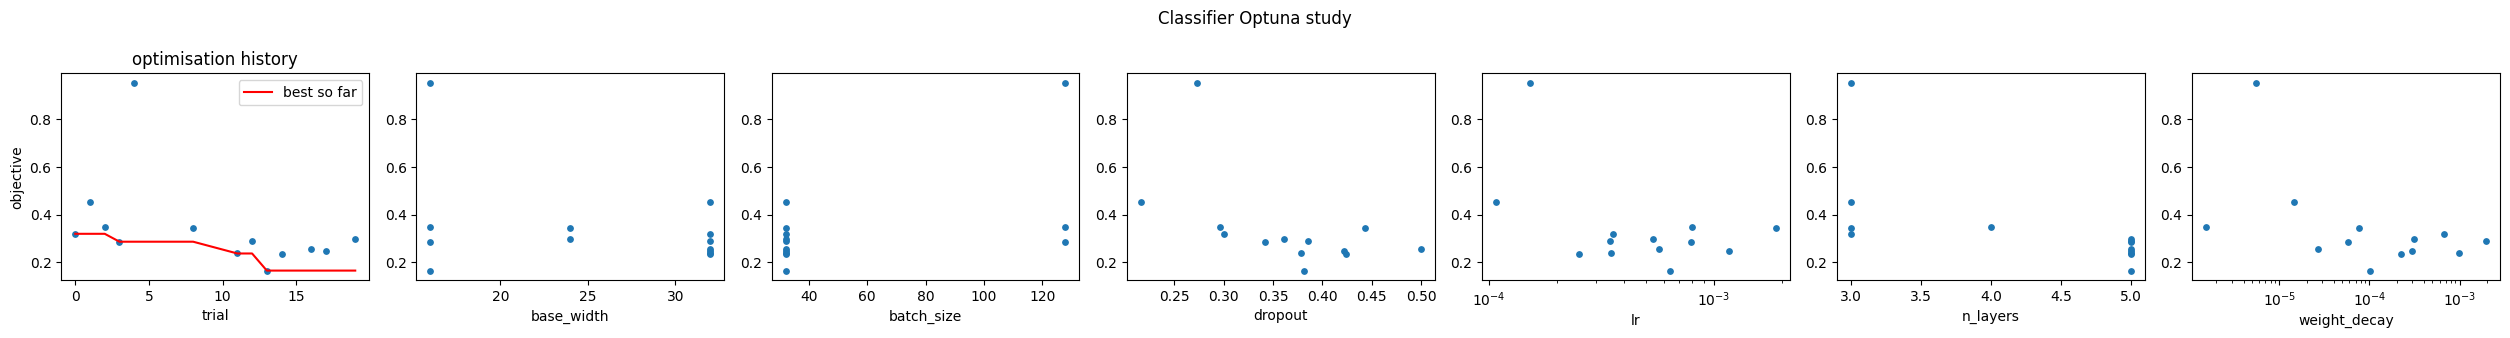

In [ ]:
# ============================================================
# Optuna: tune the classifier's learning rate, batch size, convolutional
# channel configuration (n_layers x base_width), dropout, and weight decay.
# Reuses a saved result from Drive if present, so re-running this cell
# (e.g. after a disconnect) doesn't repeat an already-finished search.
# ============================================================

import optuna

N_CLF_OPTUNA_TRIALS = 20
CLF_OPTUNA_EPOCHS = 3


def clf_objective(trial):
    lr = trial.suggest_float('lr', 1e-4, 3e-3, log=True)
    batch_size = trial.suggest_categorical('batch_size', [32, 64, 128])
    n_layers = trial.suggest_int('n_layers', 3, 5)
    base_width = trial.suggest_categorical('base_width', [16, 24, 32])
    dropout = trial.suggest_float('dropout', 0.0, 0.5)
    weight_decay = trial.suggest_float('weight_decay', 1e-6, 1e-2, log=True)

    set_seed(SEED)
    model = CorruptionClassifier(n_layers=n_layers, base_width=base_width, dropout=dropout).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    train_length = (len(train_paths) // batch_size) * batch_size
    trial_train_loader = make_loader(ClassifierTrainDataset(train_paths, train_length),
                                      batch_size, shuffle=False, drop_last=True)
    trial_val_loader = make_loader(val_ds, batch_size, shuffle=False, drop_last=False)

    best_val = float('inf')
    for epoch in range(CLF_OPTUNA_EPOCHS):
        train_one_epoch_classifier(model, trial_train_loader, optimizer, DEVICE)
        val_result = evaluate_classifier(model, trial_val_loader, DEVICE)
        best_val = min(best_val, val_result['loss'])
        trial.report(val_result['loss'], epoch)
        if trial.should_prune():
            raise optuna.TrialPruned()
    return best_val


CLF_OPTUNA_BEST_PATH = os.path.join(RESULTS_DIR, 'classifier_optuna_best.json')

if os.path.exists(CLF_OPTUNA_BEST_PATH):
    with open(CLF_OPTUNA_BEST_PATH) as f:
        CLF_BEST_PARAMS = json.load(f)['best_params']
    print('Reusing saved classifier Optuna result from Drive:')
    print(CLF_BEST_PARAMS)
else:
    clf_study = optuna.create_study(direction='minimize',
                                     sampler=optuna.samplers.TPESampler(seed=SEED),
                                     pruner=optuna.pruners.MedianPruner(n_warmup_steps=1))
    clf_study.optimize(clf_objective, n_trials=N_CLF_OPTUNA_TRIALS)

    print('Classifier: completed trials:',
          len([t for t in clf_study.trials if t.state == optuna.trial.TrialState.COMPLETE]))
    print('Best val loss:', clf_study.best_trial.value)
    print('Best hyperparameters:', clf_study.best_trial.params)

    with open(CLF_OPTUNA_BEST_PATH, 'w') as f:
        json.dump({'best_value': clf_study.best_trial.value, 'best_params': clf_study.best_trial.params}, f, indent=2)
    with open(os.path.join(RESULTS_DIR, 'classifier_optuna_all_trials.json'), 'w') as f:
        json.dump([{'number': t.number, 'value': t.value, 'params': t.params, 'state': str(t.state)}
                   for t in clf_study.trials], f, indent=2)

    CLF_BEST_PARAMS = clf_study.best_trial.params

# Optuna summary plots from the saved trial log
def plot_optuna_trials(json_path, title, save_path):
    """Optimisation history and objective vs each hyperparameter, from the saved trial log."""
    if not os.path.exists(json_path):
        print('No trial log found at', json_path); return
    with open(json_path) as f:
        trials = json.load(f)
    done = sorted([t for t in trials if 'COMPLETE' in t['state']], key=lambda t: t['number'])
    print(f"{title}: {len(trials)} trials ({len(done)} complete, {sum('PRUNED' in t['state'] for t in trials)} pruned)")
    params = sorted({k for t in done for k in t['params']})
    fig, axes = plt.subplots(1, 1 + len(params), figsize=(3.6 * (1 + len(params)), 3.4))
    vals = [t['value'] for t in done]
    axes[0].scatter([t['number'] for t in done], vals, s=15)
    axes[0].plot([t['number'] for t in done], np.minimum.accumulate(vals), 'r-', label='best so far')
    axes[0].set_xlabel('trial'); axes[0].set_ylabel('objective'); axes[0].set_title('optimisation history'); axes[0].legend()
    for ax, p in zip(axes[1:], params):
        ax.scatter([t['params'][p] for t in done], vals, s=15); ax.set_xlabel(p)
        if p in ('lr', 'weight_decay', 'g_lr', 'd_lr', 'lambda_c', 'lambda_b', 'lambda_l1', 'tau'):
            ax.set_xscale('log')
    fig.suptitle(title); plt.tight_layout()
    plt.savefig(save_path, dpi=120, bbox_inches='tight'); plt.show()

print('Search space: lr [1e-4, 3e-3] log | batch_size {32, 64, 128} | n_layers [3, 5] | base_width {16, 24, 32} | '
      'dropout [0, 0.5] | weight_decay [1e-6, 1e-2] log')
print('Best classifier configuration:', CLF_BEST_PARAMS)
plot_optuna_trials(os.path.join(RESULTS_DIR, 'classifier_optuna_all_trials.json'), 'Classifier Optuna study',
                   os.path.join(RESULTS_DIR, 'classifier_optuna_plots.png'))

## 10. Final classifier training (resumable) + full metrics report
Reports overall accuracy, macro-averaged precision/recall/F1, per-class metrics, and a normalized confusion matrix. Explicitly detects and skips a training loop that already finished in a prior session.

Resuming classifier training from /content/drive/MyDrive/task2_artifacts_correct/checkpoints/classifier_last.pt, epoch 31, best_val_loss so far 0.0461
✅ Classifier training already complete (epoch 30/30). Skipping training loop.
Loaded best classifier checkpoint, val_loss = 0.04605554520031032

=== Classifier test metrics ===
Overall accuracy: 0.9827
Macro precision:  0.9642
Macro recall:     0.9835
Macro F1:         0.9727

Per-class:
  clean          precision=0.862 recall=0.988 f1=0.921 support=3669
  salt_pepper    precision=1.000 recall=1.000 f1=1.000 support=11007
  gaussian_blur  precision=0.996 recall=0.963 f1=0.979 support=11007
  occlusion      precision=0.999 recall=0.983 f1=0.991 support=11007


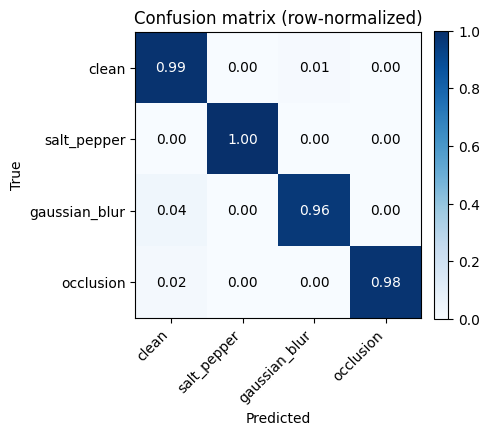

               precision  recall      f1  support
clean             0.8620  0.9877  0.9206   3669.0
salt_pepper       1.0000  1.0000  1.0000  11007.0
gaussian_blur     0.9957  0.9631  0.9791  11007.0
occlusion         0.9991  0.9832  0.9911  11007.0


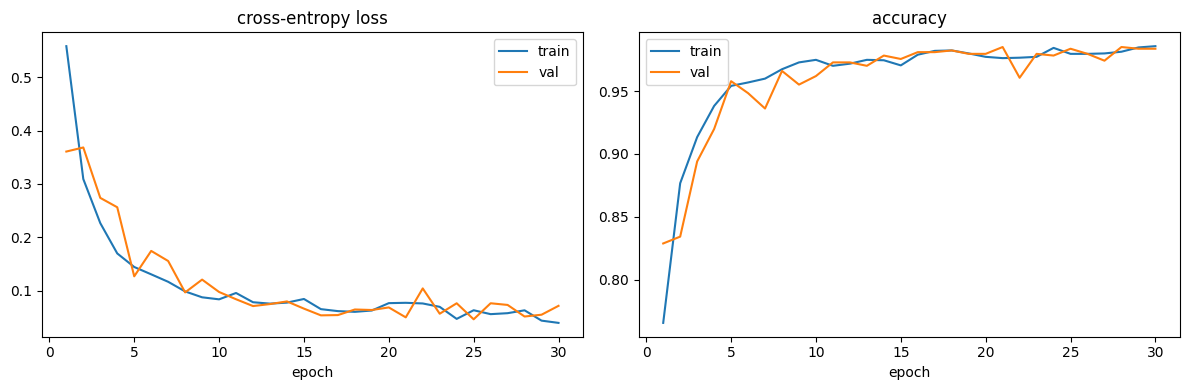

In [ ]:
# ============================================================
# Final classifier training -- resumable via Drive.
# If training already completed in a prior session, this skips the loop
# entirely (explicit check, not just an empty range()) and goes straight
# to reloading the best checkpoint and reporting metrics.
# ============================================================

CLF_FINAL_EPOCHS = 30
CLF_PATIENCE = 8
CLF_CKPT_NAME = 'classifier_best.pt'
CLF_CKPT_LAST_NAME = 'classifier_last.pt'

lr = CLF_BEST_PARAMS['lr']
batch_size = CLF_BEST_PARAMS['batch_size']
n_layers = CLF_BEST_PARAMS['n_layers']
base_width = CLF_BEST_PARAMS['base_width']
dropout = CLF_BEST_PARAMS['dropout']
weight_decay = CLF_BEST_PARAMS['weight_decay']

set_seed(SEED)
classifier = CorruptionClassifier(n_layers=n_layers, base_width=base_width, dropout=dropout).to(DEVICE)
clf_optimizer = torch.optim.AdamW(classifier.parameters(), lr=lr, weight_decay=weight_decay)

start_epoch = 1
best_val_loss = float('inf')
epochs_no_improve = 0
clf_history = []

resume_path = find_file(CLF_CKPT_LAST_NAME)
if resume_path is not None:
    ckpt = torch.load(resume_path, map_location=DEVICE)
    classifier.load_state_dict(ckpt['model_state'])
    clf_optimizer.load_state_dict(ckpt['optimizer_state'])
    start_epoch = ckpt['epoch'] + 1
    best_val_loss = ckpt['best_val_loss']
    epochs_no_improve = ckpt['epochs_no_improve']
    clf_history = ckpt.get('history', [])
    print(f'Resuming classifier training from {resume_path}, epoch {start_epoch}, '
          f'best_val_loss so far {best_val_loss:.4f}')
else:
    print('No prior classifier checkpoint found -- training from scratch.')

train_length = (len(train_paths) // batch_size) * batch_size
clf_train_loader = make_loader(ClassifierTrainDataset(train_paths, train_length),
                                batch_size, shuffle=False, drop_last=True)
clf_val_loader = make_loader(val_ds, batch_size, shuffle=False, drop_last=False)

if start_epoch > CLF_FINAL_EPOCHS:
    print(f'✅ Classifier training already complete (epoch {start_epoch - 1}/{CLF_FINAL_EPOCHS}). '
          f'Skipping training loop.')
else:
    for epoch in range(start_epoch, CLF_FINAL_EPOCHS + 1):
        t0 = time.time()
        train_metrics = train_one_epoch_classifier(classifier, clf_train_loader, clf_optimizer, DEVICE)
        val_result = evaluate_classifier(classifier, clf_val_loader, DEVICE)
        val_acc = accuracy_score(val_result['labels'], val_result['preds'])

        clf_history.append({'epoch': epoch, 'train_loss': train_metrics['loss'], 'train_acc': train_metrics['acc'],
                             'val_loss': val_result['loss'], 'val_acc': val_acc, 'time_s': time.time() - t0})
        print(f"Epoch {epoch:03d} | train_loss {train_metrics['loss']:.4f} acc {train_metrics['acc']:.3f} "
              f"| val_loss {val_result['loss']:.4f} val_acc {val_acc:.3f} | time {time.time() - t0:.1f}s")

        improved = val_result['loss'] < best_val_loss - 1e-5
        if improved:
            best_val_loss = val_result['loss']
            epochs_no_improve = 0
            save_checkpoint({
                'model_state': classifier.state_dict(),
                'config': {'n_layers': n_layers, 'base_width': base_width, 'dropout': dropout, 'img_size': IMG_SIZE},
                'epoch': epoch, 'val_loss': best_val_loss,
            }, CLF_CKPT_NAME)
            if epoch == start_epoch:
                verify_checkpoint(CLF_CKPT_NAME)
        else:
            epochs_no_improve += 1

        save_checkpoint({
            'model_state': classifier.state_dict(), 'optimizer_state': clf_optimizer.state_dict(),
            'config': {'n_layers': n_layers, 'base_width': base_width, 'dropout': dropout, 'img_size': IMG_SIZE},
            'epoch': epoch, 'best_val_loss': best_val_loss, 'epochs_no_improve': epochs_no_improve,
            'history': clf_history,
        }, CLF_CKPT_LAST_NAME)

        if epochs_no_improve >= CLF_PATIENCE:
            print(f'Early stopping at epoch {epoch} (no improvement for {CLF_PATIENCE} epochs).')
            break

    with open(os.path.join(RESULTS_DIR, 'classifier_training_history.json'), 'w') as f:
        json.dump(clf_history, f, indent=2)

# ---- reload best checkpoint for evaluation/export ----
best_path = find_file(CLF_CKPT_NAME)
clf_ckpt = torch.load(best_path, map_location=DEVICE)
classifier = CorruptionClassifier(**clf_ckpt['config']).to(DEVICE)
classifier.load_state_dict(clf_ckpt['model_state'])
classifier.eval()
print('Loaded best classifier checkpoint, val_loss =', clf_ckpt['val_loss'])

# ---- full metrics report on the test set ----
clf_test_loader = make_loader(test_ds, batch_size=64, shuffle=False, drop_last=False)
test_result = evaluate_classifier(classifier, clf_test_loader, DEVICE)
metrics = classification_metrics(test_result['preds'], test_result['labels'])

print(f"\n=== Classifier test metrics ===")
print(f"Overall accuracy: {metrics['accuracy']:.4f}")
print(f"Macro precision:  {metrics['macro_precision']:.4f}")
print(f"Macro recall:     {metrics['macro_recall']:.4f}")
print(f"Macro F1:         {metrics['macro_f1']:.4f}")
print("\nPer-class:")
for cname, m in metrics['per_class'].items():
    print(f"  {cname:14s} precision={m['precision']:.3f} recall={m['recall']:.3f} "
          f"f1={m['f1']:.3f} support={m['support']}")

with open(os.path.join(RESULTS_DIR, 'classifier_test_metrics.json'), 'w') as f:
    json.dump(metrics, f, indent=2)

plot_confusion_matrix(np.array(metrics['confusion_matrix_normalized']), CORRUPTION_TYPES,
                       os.path.join(RESULTS_DIR, 'classifier_confusion_matrix.png'))

# Per-class table and classifier training curves
import pandas as pd
print(pd.DataFrame(metrics['per_class']).T.round(4).to_string())
if clf_history:
    h = pd.DataFrame(clf_history)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(h['epoch'], h['train_loss'], label='train'); axes[0].plot(h['epoch'], h['val_loss'], label='val'); axes[0].set_title('cross-entropy loss')
    axes[1].plot(h['epoch'], h['train_acc'], label='train'); axes[1].plot(h['epoch'], h['val_acc'], label='val'); axes[1].set_title('accuracy')
    for a in axes: a.set_xlabel('epoch'); a.legend()
    plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, 'classifier_training_curves.png'), dpi=120, bbox_inches='tight'); plt.show()

**Confusion-matrix interpretation.** Salt-and-pepper is never confused, because isolated pure black/white pixels are unique to it. Almost all errors are corrupted images predicted as **clean**: mostly low-severity blur (k=3, σ=0.7, a very slight softening at 128×128) and small occlusions that fall on naturally dark regions such as black fur or shadow. This is why *clean* has high recall (0.988) but lower precision (0.862). Corrupted classes are almost never confused with each other.

## 11. Specialist autoencoder architecture + type-specific losses
A spatial-bottleneck convolutional autoencoder (no flatten-to-vector bottleneck, no `ConvTranspose2d`) — the correctness of this design was independently verified before use. On top of the standard L1+SSIM reconstruction loss: a Sobel **edge loss** for the blur specialist (directly penalizes remaining softness) and a VGG **perceptual loss** for the occlusion specialist (feature-space loss, discourages the flat/blurry fill pixel losses default to for inpainting — the same reason Context Encoders and pix2pix both add a non-pixel loss term). Salt-and-pepper is a local, low-ambiguity corruption where plain L1+SSIM is sufficient.

In [ ]:
# ============================================================
# Specialist autoencoder architecture. Each specialist only ever sees ONE
# corruption type, so there's no need for the degradation-conditioning
# machinery from Task 1's universal model -- a plain spatial-bottleneck
# convolutional autoencoder is the right amount of complexity here.
# Same fixes as Task 1's corrected architecture: a genuine SPATIAL
# bottleneck (not flattened to a vector) and resize-convolution upsampling
# (not ConvTranspose2d), both of which avoid blurry reconstructions.
# ============================================================

class ResBlock(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.conv1 = nn.Conv2d(ch, ch, 3, padding=1)
        self.norm1 = nn.GroupNorm(8, ch)
        self.conv2 = nn.Conv2d(ch, ch, 3, padding=1)
        self.norm2 = nn.GroupNorm(8, ch)

    def forward(self, x):
        h = F.relu(self.norm1(self.conv1(x)))
        h = self.norm2(self.conv2(h))
        return F.relu(x + h)


class DownBlock(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.conv = nn.Conv2d(cin, cout, 4, stride=2, padding=1)
        self.norm = nn.GroupNorm(8, cout)

    def forward(self, x):
        return F.relu(self.norm(self.conv(x)))


class UpBlock(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.conv = nn.Conv2d(cin, cout, 3, padding=1)
        self.norm = nn.GroupNorm(8, cout)

    def forward(self, x):
        x = F.interpolate(x, scale_factor=2, mode='nearest')
        return F.relu(self.norm(self.conv(x)))


class SpecialistEncoder(nn.Module):
    def __init__(self, base_channels=48, bottleneck_channels=128, dropout=0.1, n_res_blocks=2):
        super().__init__()
        c = base_channels
        self.stem = nn.Sequential(nn.Conv2d(3, c, 3, padding=1), nn.GroupNorm(8, c), nn.ReLU(inplace=True))
        self.down1 = DownBlock(c, c * 2)
        self.down2 = DownBlock(c * 2, c * 4)
        self.down3 = DownBlock(c * 4, c * 8)
        self.down4 = DownBlock(c * 8, c * 8)
        self.res = nn.Sequential(*[ResBlock(c * 8) for _ in range(n_res_blocks)])
        self.dropout = nn.Dropout2d(dropout)
        self.squeeze = nn.Conv2d(c * 8, bottleneck_channels, 1)

    def forward(self, x):
        h = self.stem(x)
        h = self.down1(h); h = self.down2(h); h = self.down3(h); h = self.down4(h)
        h = self.res(h)
        h = self.dropout(h)
        return self.squeeze(h)


class SpecialistDecoder(nn.Module):
    def __init__(self, base_channels=48, bottleneck_channels=128, dropout=0.1, n_res_blocks=2):
        super().__init__()
        c = base_channels
        self.expand = nn.Conv2d(bottleneck_channels, c * 8, 1)
        self.res = nn.Sequential(*[ResBlock(c * 8) for _ in range(n_res_blocks)])
        self.up1 = UpBlock(c * 8, c * 8)
        self.up2 = UpBlock(c * 8, c * 4)
        self.up3 = UpBlock(c * 4, c * 2)
        self.up4 = UpBlock(c * 2, c)
        self.dropout = nn.Dropout2d(dropout)
        self.out_conv = nn.Conv2d(c, 3, 3, padding=1)

    def forward(self, z):
        h = self.expand(z)
        h = self.res(h)
        h = self.up1(h); h = self.up2(h); h = self.up3(h); h = self.up4(h)
        h = self.dropout(h)
        return torch.sigmoid(self.out_conv(h))


class SpecialistAutoencoder(nn.Module):
    def __init__(self, base_channels=48, bottleneck_channels=128, dropout=0.1, n_res_blocks=2, img_size=IMG_SIZE):
        super().__init__()
        assert img_size % 16 == 0
        self.encoder = SpecialistEncoder(base_channels, bottleneck_channels, dropout, n_res_blocks)
        self.decoder = SpecialistDecoder(base_channels, bottleneck_channels, dropout, n_res_blocks)

    def forward(self, x):
        return self.decoder(self.encoder(x))


def combined_loss(x_hat, x, alpha):
    l1 = F.l1_loss(x_hat, x)
    s = ssim_metric(x_hat, x, data_range=1.0, size_average=True)
    return alpha * l1 + (1 - alpha) * (1 - s), l1.detach(), s.detach()


# ============================================================
# Type-specific auxiliary losses. Plain L1+SSIM alone tends to converge to
# blurry, "regression-to-the-mean" solutions -- this is a well-documented
# property of pixel-wise losses (see Pathak et al., "Context Encoders",
# CVPR 2016, and Isola et al., "pix2pix", CVPR 2017: both motivate
# adding a non-pixel loss specifically because L1/L2 alone produces blur).
# It matters most for the two hardest restoration problems here:
#   - Deblurring needs to recover HIGH FREQUENCIES specifically -- a Sobel
#     edge loss directly penalizes remaining softness that L1/SSIM barely
#     notice (a small per-pixel error can still mean a visibly soft edge).
#   - Occlusion inpainting has to HALLUCINATE texture in a masked region --
#     pixel losses average over plausible textures (blurry fill); a VGG
#     perceptual loss operates in feature space, where "plausible texture"
#     solutions look different from "flat average" solutions, discouraging
#     the flat/blurry fill.
# Salt-and-pepper is a local, low-ambiguity corruption (each bad pixel has
# unambiguous nearby context) -- plain L1+SSIM is normally sufficient.
# ============================================================

class SobelEdgeLoss(nn.Module):
    """L1 distance between Sobel gradients of x_hat and x. Penalizes
    remaining blur directly, independent of overall pixel error."""
    def __init__(self):
        super().__init__()
        kx = torch.tensor([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]]).view(1, 1, 3, 3)
        ky = kx.transpose(2, 3)
        self.register_buffer('kx', kx.repeat(3, 1, 1, 1))
        self.register_buffer('ky', ky.repeat(3, 1, 1, 1))

    def forward(self, x_hat, x):
        gx_hat = F.conv2d(x_hat, self.kx, padding=1, groups=3)
        gy_hat = F.conv2d(x_hat, self.ky, padding=1, groups=3)
        gx = F.conv2d(x, self.kx, padding=1, groups=3)
        gy = F.conv2d(x, self.ky, padding=1, groups=3)
        return F.l1_loss(gx_hat, gx) + F.l1_loss(gy_hat, gy)


class VGGPerceptualLoss(nn.Module):
    """L1 distance between VGG16 feature maps of x_hat and x, at a few
    early/mid layers. Operates in feature space rather than pixel space,
    which discourages the flat/blurry-average fill that pure pixel losses
    tend to produce for inpainting."""
    def __init__(self, layer_idxs=(3, 8, 15)):
        super().__init__()
        import torchvision.models as tvm
        try:
            weights = tvm.VGG16_Weights.DEFAULT
            vgg = tvm.vgg16(weights=weights).features
        except Exception as e:
            print(f'WARNING: could not download pretrained VGG16 weights ({e}). '
                  f'Falling back to randomly-initialized VGG16 -- the perceptual loss will '
                  f'still run and provide SOME feature-space signal, but will be markedly '
                  f'less effective than with ImageNet-pretrained weights. Check that Internet '
                  f'is turned ON in this notebook\'s settings and re-run this cell.')
            vgg = tvm.vgg16(weights=None).features
        self.slices = nn.ModuleList()
        prev = 0
        for idx in layer_idxs:
            self.slices.append(vgg[prev:idx + 1])
            prev = idx + 1
        for p in self.parameters():
            p.requires_grad = False
        self.register_buffer('mean', torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer('std', torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x_hat, x):
        x_hat_n = (x_hat - self.mean) / self.std
        x_n = (x - self.mean) / self.std
        loss = 0.0
        h_hat, h = x_hat_n, x_n
        for sl in self.slices:
            h_hat = sl(h_hat)
            h = sl(h)
            loss = loss + F.l1_loss(h_hat, h)
        return loss


# Fixed, documented default weights for the auxiliary losses. Reasonable
# starting points from common practice (perceptual-loss weights are
# typically small relative to the pixel loss, since VGG feature
# magnitudes are on a different scale); tune further if needed.
AUX_LOSS_WEIGHTS = {
    'salt_pepper': {'edge': 0.0, 'perceptual': 0.0},
    'gaussian_blur': {'edge': 0.15, 'perceptual': 0.0},
    'occlusion': {'edge': 0.0, 'perceptual': 0.10},
}

edge_loss_fn = SobelEdgeLoss()
_vgg_loss_fn = None  # lazily constructed (only occlusion needs it) -- see get_vgg_loss()


def get_vgg_loss(device):
    global _vgg_loss_fn
    if _vgg_loss_fn is None:
        _vgg_loss_fn = VGGPerceptualLoss().to(device)
    return _vgg_loss_fn


def specialist_total_loss(x_hat, clean, alpha, ctype, device):
    recon_loss, l1, s = combined_loss(x_hat, clean, alpha)
    total = recon_loss
    extras = {}
    w = AUX_LOSS_WEIGHTS[ctype]
    if w['edge'] > 0:
        e = edge_loss_fn.to(device)(x_hat, clean)
        total = total + w['edge'] * e
        extras['edge'] = e.item()
    if w['perceptual'] > 0:
        p = get_vgg_loss(device)(x_hat, clean)
        total = total + w['perceptual'] * p
        extras['perceptual'] = p.item()
    return total, l1, s, extras



_test_model = SpecialistAutoencoder()
_test_out = _test_model(torch.rand(2, 3, IMG_SIZE, IMG_SIZE))
print('Specialist output shape:', _test_out.shape,
      '| params:', sum(p.numel() for p in _test_model.parameters()))
del _test_model, _test_out


Specialist output shape: torch.Size([2, 3, 128, 128]) | params: 16838531


## 12. Specialist training / evaluation helpers, plus debugging tools
`overfit_sanity_check()`, `output_diversity_check()`, `save_qualitative_snapshot()` — see the note at the top of this notebook.

In [ ]:
# ============================================================
# Specialist training / evaluation helpers, now using the type-specific
# auxiliary losses, PLUS debugging instrumentation:
#   - overfit_sanity_check(): THE definitive test for "is this an
#     architecture/training-loop bug, or a training-budget issue?"
#   - output_diversity_check(): detects the classic silent failure mode
#     where a network collapses to predicting ~the same average image
#     regardless of input.
#   - save_qualitative_snapshot(): saves a small before/after grid every
#     few epochs so you can SEE whether/when sharpening kicks in, instead
#     of only staring at loss numbers.
# ============================================================

def train_one_epoch_specialist(model, loader, optimizer, alpha, ctype, device):
    model.train()
    total_loss, total_l1, total_ssim, n = 0.0, 0.0, 0.0, 0
    for batch in loader:
        clean = batch['clean'].to(device, non_blocking=True)
        corrupted = batch['corrupted'].to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        x_hat = model(corrupted)
        loss, l1, s, extras = specialist_total_loss(x_hat, clean, alpha, ctype, device)
        loss.backward()
        optimizer.step()
        bs = clean.size(0)
        total_loss += loss.item() * bs
        total_l1 += l1.item() * bs
        total_ssim += s.item() * bs
        n += bs
    return {'loss': total_loss / max(n, 1), 'l1': total_l1 / max(n, 1), 'ssim': total_ssim / max(n, 1)}


@torch.no_grad()
def evaluate_specialist(model, loader, alpha, ctype, device):
    model.eval()
    total_loss, total_l1, total_ssim, n = 0.0, 0.0, 0.0, 0
    for batch in loader:
        clean = batch['clean'].to(device, non_blocking=True)
        corrupted = batch['corrupted'].to(device, non_blocking=True)
        x_hat = model(corrupted)
        loss, l1, s, extras = specialist_total_loss(x_hat, clean, alpha, ctype, device)
        bs = clean.size(0)
        total_loss += loss.item() * bs
        total_l1 += l1.item() * bs
        total_ssim += s.item() * bs
        n += bs
    return {'loss': total_loss / max(n, 1), 'l1': total_l1 / max(n, 1), 'ssim': total_ssim / max(n, 1)}


def make_specialist_val_loader(ctype, batch_size=64):
    """Uses the DEDICATED per-specialist validation manifest (full val
    split, not a quarter of it) -- see the note in the manifest cell."""
    return make_loader(PetManifestDataset(specialist_val_manifest[ctype]), batch_size,
                        shuffle=False, drop_last=False)


# ---------------- Debugging tools ----------------

def overfit_sanity_check(model_ctor, ctype, n_images=8, n_steps=900, lr=3e-3, device=DEVICE, verbose=True):
    """Can this exact architecture + loss + training loop memorize a
    handful of real images to near-perfect reconstruction? Run this BEFORE
    trusting any "still blurry" result on the full dataset.

    IMPORTANT: convergence speed depends heavily on image resolution. This
    default (900 steps) is calibrated for 128x128 images -- a lower
    resolution converges much faster and a stricter n_steps would be a
    false alarm; a higher resolution may need more. The verdict below also
    reports the loss TREND (still dropping vs. plateaued), not just a
    pass/fail at a fixed step count, because L1+SSIM has a well-documented
    slow warm-up (loss can sit nearly flat for a couple hundred steps
    before SSIM's structural gradient "catches" and drops quickly) --
    stopping the check too early looks identical to a real bug but isn't.
      - PASS (l1 near 0, ssim near 1): the pipeline is structurally
        correct. Blur on the full dataset is a training-budget /
        validation-noise / regularization-strength issue, NOT a code bug.
      - FAIL but still trending down at the end: likely just needs more
        steps -- not conclusive evidence of a bug on its own.
      - FAIL and flat/plateaued for the last 25% of steps: THIS is the
        real warning sign -- investigate learning rate, bottleneck size,
        and gradient flow before trusting a long training run.
    Uses dropout=0 deliberately (dropout is a regularizer for the FULL
    dataset; it correctly caps how well a small batch can be memorized,
    which would make this test meaningless)."""
    torch.manual_seed(0)
    model = model_ctor(dropout=0.0).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)

    small_paths = train_paths[:n_images]
    clean_imgs = torch.stack([to_tensor(get_clean_image(p)) for p in small_paths]).to(device)
    rng = np.random.default_rng(0)
    corrupted_list = []
    for img_np in [get_clean_image(p) for p in small_paths]:
        if ctype == 'salt_pepper':
            corrupted_list.append(apply_salt_pepper(img_np, 0.08, rng))
        elif ctype == 'gaussian_blur':
            corrupted_list.append(apply_gaussian_blur(img_np, 5, 1.5))
        else:
            rects = sample_rectangles(IMG_SIZE, IMG_SIZE, 2, 0.2, rng)
            corrupted_list.append(apply_occlusion(img_np, rects))
    corrupted_imgs = torch.stack([to_tensor(c) for c in corrupted_list]).to(device)

    ssim_trace = []
    for step in range(n_steps):
        opt.zero_grad()
        x_hat = model(corrupted_imgs)
        loss, l1, s, _ = specialist_total_loss(x_hat, clean_imgs, 0.8, ctype, device)
        loss.backward()
        opt.step()
        ssim_trace.append(s.item())
        if verbose and (step % max(1, n_steps // 4) == 0):
            print(f'  [{ctype} overfit-check] step {step:4d}  loss={loss.item():.4f}  '
                  f'l1={l1.item():.4f}  ssim={s.item():.4f}')

    last_l1, last_ssim = l1.item(), s.item()
    passed = last_l1 < 0.03 and last_ssim > 0.95

    # trend check: compare mean ssim over the last quarter vs the quarter before it
    q = max(1, n_steps // 4)
    still_improving = np.mean(ssim_trace[-q:]) > np.mean(ssim_trace[-2*q:-q]) + 0.01

    if passed:
        verdict = 'PASS'
    elif still_improving:
        verdict = 'INCOMPLETE (still improving -- likely just needs more steps, not conclusive)'
    else:
        verdict = 'FAIL (plateaued -- this IS a warning sign)'
    print(f'[{ctype}] overfit sanity check: {verdict} (final l1={last_l1:.4f}, ssim={last_ssim:.4f})')
    if not passed and not still_improving:
        print(f'  ^^ WARNING: plateaued below target after {n_steps} steps with NO further improvement '
              f'in the last {q} steps. This points to a real bug -- check learning rate, bottleneck '
              f'size, and gradient flow before training on the full dataset.')
    return passed, last_l1, last_ssim


@torch.no_grad()
def output_diversity_check(model, ctype, n_images=8, device=DEVICE):
    """Detects mean-collapse: a network that ignores its input and always
    predicts ~the same average image. Compares how much the OUTPUTS vary
    across different input images to how much the INPUTS vary -- if inputs
    are diverse but outputs are nearly identical, that's mean-collapse,
    which looks exactly like 'everything is blurry' but is a distinct and
    more serious failure mode (worth knowing which one you have)."""
    model.eval()
    paths = train_paths[:n_images]
    imgs = torch.stack([to_tensor(get_clean_image(p)) for p in paths]).to(device)
    x_hat = model(imgs)
    input_std = imgs.flatten(1).std(dim=0).mean().item()
    output_std = x_hat.flatten(1).std(dim=0).mean().item()
    ratio = output_std / (input_std + 1e-8)
    print(f'[{ctype}] output diversity check: input std={input_std:.4f}, output std={output_std:.4f}, '
          f'ratio={ratio:.2f} (near 0 = mean-collapse warning; near 1 = healthy input-dependence)')
    return ratio


def save_qualitative_snapshot(model, ctype, epoch, save_dir):
    """Saves a small before/after grid so you can SEE when/if sharpening
    starts, rather than only reading loss numbers epoch to epoch."""
    model.eval()
    sample = PetManifestDataset(specialist_val_manifest[ctype][:4])
    fig, axes = plt.subplots(4, 3, figsize=(7, 9))
    with torch.no_grad():
        for i in range(4):
            item = sample[i]
            clean = item['clean'].unsqueeze(0).to(DEVICE)
            corrupted = item['corrupted'].unsqueeze(0).to(DEVICE)
            x_hat = model(corrupted).clamp(0, 1)
            for col, img in enumerate([clean[0], corrupted[0], x_hat[0]]):
                axes[i, col].imshow(img.cpu().permute(1, 2, 0).numpy())
                axes[i, col].axis('off')
                if i == 0:
                    axes[i, col].set_title(['clean', 'corrupted', 'restored'][col])
    fig.suptitle(f'{ctype} -- epoch {epoch}')
    plt.tight_layout()
    os.makedirs(save_dir, exist_ok=True)
    path = os.path.join(save_dir, f'{ctype}_epoch{epoch:03d}.png')
    plt.savefig(path, dpi=90, bbox_inches='tight')
    plt.close(fig)
    return path


## 13. Shared Optuna search for the specialist architecture
A single search (using the gaussian_blur specialist as a representative proxy) identifies a common architecture: learning rate, bottleneck size, channel configuration, batch size, and the L1-to-SSIM weighting α. Each specialist is then trained independently with this shared architecture but fresh random initialization. Reuses a saved result from Drive if present.

Reusing saved specialist Optuna result from Drive:
{'lr': 0.00010299673377649191, 'batch_size': 64, 'bottleneck_channels': 128, 'base_channels': 24, 'n_res_blocks': 3, 'dropout': 0.16997817535270465, 'alpha': 0.9473885841476932}
Search space: lr [1e-4, 3e-3] log | batch_size {32, 64, 128} | bottleneck_channels {64, 96, 128, 192} | base_channels {24, 32, 48, 64} | n_res_blocks [1, 3] | dropout | alpha [0.5, 0.95]
Shared specialist Optuna study: 20 trials (15 complete, 5 pruned)


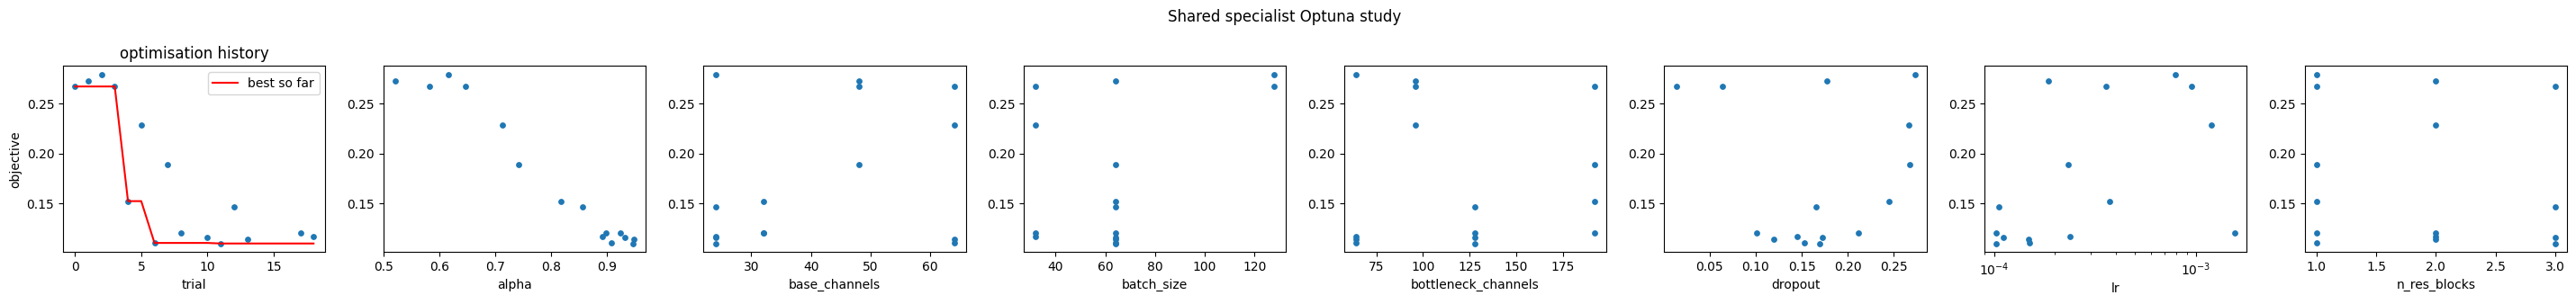

In [ ]:
# ============================================================
# Shared Optuna search for the specialist architecture.
# Per the assignment, a single search identifies a common architecture,
# which is then used to train each of the 3 specialists independently
# (fresh random init, single corruption type each). We use the
# gaussian_blur specialist as the search proxy -- blur removal is the
# hardest of the three restoration problems (salt-and-pepper is local and
# occlusion has a hard mask boundary; blur requires the most genuine
# high-frequency reconstruction), so a config that works well for it
# should be architecturally sound for the other two as well.
# ============================================================

N_SPEC_OPTUNA_TRIALS = 20
SPEC_OPTUNA_EPOCHS = 4
SPEC_PROXY_CTYPE = 'gaussian_blur'
SPEC_OPTUNA_BEST_PATH = os.path.join(RESULTS_DIR, 'specialist_optuna_best.json')

if os.path.exists(SPEC_OPTUNA_BEST_PATH):
    with open(SPEC_OPTUNA_BEST_PATH) as f:
        SPEC_BEST_PARAMS = json.load(f)['best_params']
    print('Reusing saved specialist Optuna result from Drive:')
    print(SPEC_BEST_PARAMS)
else:
    # ---- Debug gate: confirm the architecture can even memorize a tiny batch
    # before spending an entire Optuna search on it. If this fails, something
    # is structurally wrong (see overfit_sanity_check's docstring) and no
    # amount of hyperparameter search will fix it. ----
    _passed, _l1, _ssim = overfit_sanity_check(
        lambda dropout: SpecialistAutoencoder(base_channels=32, bottleneck_channels=96, n_res_blocks=2, dropout=dropout),
        ctype=SPEC_PROXY_CTYPE)
    if not _passed:
        print('Proceeding with the Optuna search anyway, but investigate the warning above first --')
        print('a failed overfit check usually means every trial below will also underperform.')

    def spec_objective(trial):
        lr = trial.suggest_float('lr', 1e-4, 3e-3, log=True)
        batch_size = trial.suggest_categorical('batch_size', [32, 64, 128])
        bottleneck_channels = trial.suggest_categorical('bottleneck_channels', [64, 96, 128, 192])
        base_channels = trial.suggest_categorical('base_channels', [24, 32, 48, 64])
        n_res_blocks = trial.suggest_int('n_res_blocks', 1, 3)
        dropout = trial.suggest_float('dropout', 0.0, 0.15)  # tightened: a high dropout combined with a
        # short Optuna trial budget was masking real convergence differences between configs
        alpha = trial.suggest_float('alpha', 0.5, 0.95)

        set_seed(SEED)
        model = SpecialistAutoencoder(base_channels=base_channels, bottleneck_channels=bottleneck_channels,
                                       dropout=dropout, n_res_blocks=n_res_blocks).to(DEVICE)
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)

        trial_train_loader = make_loader(specialist_train_ds[SPEC_PROXY_CTYPE], batch_size, shuffle=True)
        trial_val_loader = make_specialist_val_loader(SPEC_PROXY_CTYPE, batch_size)  # now the FULL val split for this type

        best_val = float('inf')
        for epoch in range(SPEC_OPTUNA_EPOCHS):
            train_one_epoch_specialist(model, trial_train_loader, optimizer, alpha, SPEC_PROXY_CTYPE, DEVICE)
            val_metrics = evaluate_specialist(model, trial_val_loader, alpha, SPEC_PROXY_CTYPE, DEVICE)
            best_val = min(best_val, val_metrics['loss'])
            trial.report(val_metrics['loss'], epoch)
            if trial.should_prune():
                raise optuna.TrialPruned()
        return best_val

    spec_study = optuna.create_study(direction='minimize',
                                      sampler=optuna.samplers.TPESampler(seed=SEED),
                                      pruner=optuna.pruners.MedianPruner(n_warmup_steps=1))
    spec_study.optimize(spec_objective, n_trials=N_SPEC_OPTUNA_TRIALS)

    print('Specialist search: completed trials:',
          len([t for t in spec_study.trials if t.state == optuna.trial.TrialState.COMPLETE]))
    print('Best val loss:', spec_study.best_trial.value)
    print('Best shared architecture:', spec_study.best_trial.params)

    with open(SPEC_OPTUNA_BEST_PATH, 'w') as f:
        json.dump({'best_value': spec_study.best_trial.value, 'best_params': spec_study.best_trial.params,
                   'proxy_ctype': SPEC_PROXY_CTYPE}, f, indent=2)
    with open(os.path.join(RESULTS_DIR, 'specialist_optuna_all_trials.json'), 'w') as f:
        json.dump([{'number': t.number, 'value': t.value, 'params': t.params, 'state': str(t.state)}
                   for t in spec_study.trials], f, indent=2)

    SPEC_BEST_PARAMS = spec_study.best_trial.params

print('Search space: lr [1e-4, 3e-3] log | batch_size {32, 64, 128} | bottleneck_channels {64, 96, 128, 192} | '
      'base_channels {24, 32, 48, 64} | n_res_blocks [1, 3] | dropout | alpha [0.5, 0.95]')
plot_optuna_trials(os.path.join(RESULTS_DIR, 'specialist_optuna_all_trials.json'), 'Shared specialist Optuna study',
                   os.path.join(RESULTS_DIR, 'specialist_optuna_plots.png'))

## 14. Train the three specialists independently (each resumable)
Runs the overfit sanity check and output-diversity check per specialist before training — read the printed verdicts before trusting a long run (the overfit check now reports whether it's genuinely plateaued vs. still improving, not just pass/fail at a fixed step count). Saves a qualitative snapshot every 5 epochs (`results/snapshots/`) and re-checks output diversity every 10 epochs during training so you can watch input-responsiveness develop over the run. Epoch ceiling 200, patience 25 (raised from 60/12 — see the note at the top of this notebook for why). Explicitly detects and skips specialists that already finished training in a prior session.


===== Debug checks: salt_pepper =====
  [salt_pepper overfit-check] step    0  loss=0.3332  l1=0.2244  ssim=0.2319
  [salt_pepper overfit-check] step  225  loss=0.1741  l1=0.0863  ssim=0.4745
  [salt_pepper overfit-check] step  450  loss=0.0707  l1=0.0340  ssim=0.7823
  [salt_pepper overfit-check] step  675  loss=0.0456  l1=0.0243  ssim=0.8695
[salt_pepper] overfit sanity check: INCOMPLETE (still improving -- likely just needs more steps, not conclusive) (final l1=0.0211, ssim=0.9073)

===== Training specialist: salt_pepper =====
Resuming from /content/drive/MyDrive/task2_artifacts_correct/checkpoints/specialist_salt_pepper_last.pt, epoch 201, best_val_loss so far 0.0570
[salt_pepper] output diversity check: input std=0.2590, output std=0.2521, ratio=0.97 (near 0 = mean-collapse warning; near 1 = healthy input-dependence)
✅ [salt_pepper] training already complete (epoch 200/200). Skipping training loop.
[salt_pepper] Loaded best checkpoint, val_loss = 0.0570

===== Debug checks: gauss

100%|██████████| 528M/528M [00:04<00:00, 118MB/s]


  [occlusion overfit-check] step    0  loss=0.6845  l1=0.2246  ssim=0.2318
  [occlusion overfit-check] step  225  loss=0.3933  l1=0.0646  ssim=0.5531
  [occlusion overfit-check] step  450  loss=0.2487  l1=0.0318  ssim=0.7838
  [occlusion overfit-check] step  675  loss=0.1681  l1=0.0241  ssim=0.8726
[occlusion] overfit sanity check: INCOMPLETE (still improving -- likely just needs more steps, not conclusive) (final l1=0.0179, ssim=0.9146)

===== Training specialist: occlusion =====
Resuming from /content/drive/MyDrive/task2_artifacts_correct/checkpoints/specialist_occlusion_last.pt, epoch 201, best_val_loss so far 0.3225
[occlusion] output diversity check: input std=0.2590, output std=0.3022, ratio=1.17 (near 0 = mean-collapse warning; near 1 = healthy input-dependence)
✅ [occlusion] training already complete (epoch 200/200). Skipping training loop.
[occlusion] Loaded best checkpoint, val_loss = 0.3225

Specialists trained this run: ['salt_pepper', 'gaussian_blur', 'occlusion']
salt_pep

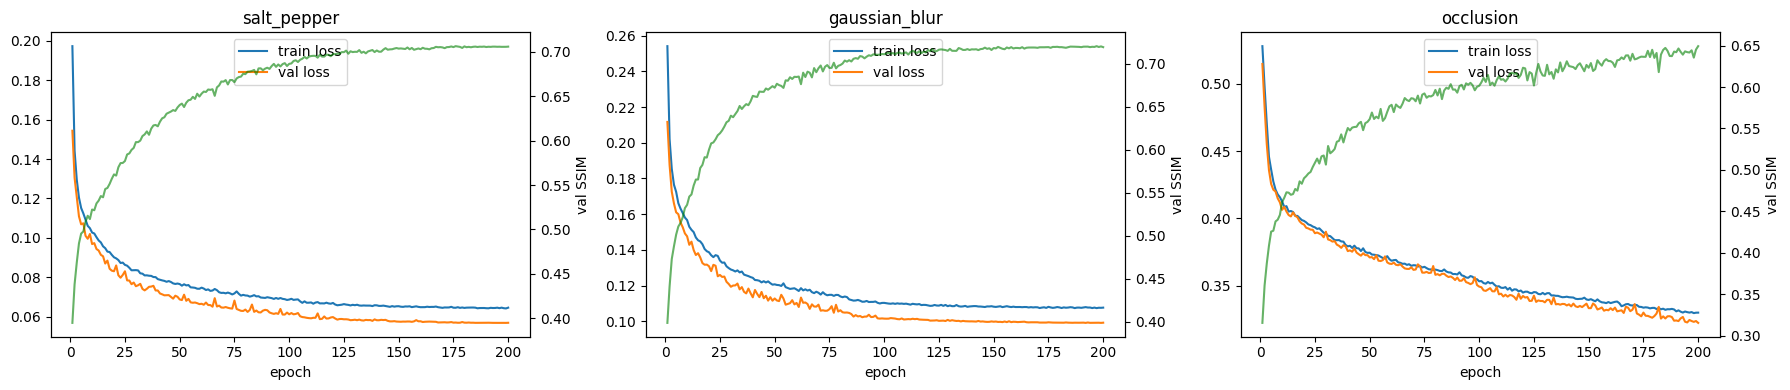

In [ ]:
# ============================================================
# Train the three specialists independently, using the shared architecture
# from the Optuna search above but fresh random initialization per
# specialist. Each has its own resumable checkpoint.
#
# Debugging built in:
#   1. Before training, an overfit sanity check + output-diversity check
#      per specialist -- confirms the pipeline is structurally sound
#      before spending a long training run on it. The diversity check
#      runs AFTER checkpoint resume, so it reflects the actual model about
#      to train, not an untrained random init.
#   2. A qualitative before/after snapshot saved every SNAPSHOT_EVERY
#      epochs -- watch these to see WHEN sharpening kicks in, rather than
#      only reading loss numbers.
#   3. A second output-diversity check every DIAGNOSTIC_EVERY epochs
#      DURING training -- lets you watch input-responsiveness develop
#      over the run instead of only checking once at the start.
#   4. Patience raised to 25 (from 12) and the epoch ceiling to 200 (from
#      60): earlier runs showed salt_pepper still improving right at the
#      old 60-epoch ceiling, and blur/occlusion exhausting the old
#      patience=12 right around epoch 53 -- both signs the old budget was
#      cutting training off before real convergence, not evidence of a
#      capacity/architecture problem.
#   5. A wall-clock budget guard so a long run always exits (and saves)
#      cleanly with time to spare before a Colab session disconnect.
# ============================================================

SPEC_FINAL_EPOCHS = 200
SPEC_PATIENCE = 25
SNAPSHOT_EVERY = 5
DIAGNOSTIC_EVERY = 10
SNAPSHOT_DIR = os.path.join(RESULTS_DIR, 'snapshots')
MAX_RUNTIME_HOURS = 10.0  # Colab sessions typically disconnect around 12h (less for free tier);
# leave margin. Drive already persists every checkpoint immediately -- no "commit" step needed,
# just re-run this cell after a disconnect and it resumes automatically.

spec_lr = SPEC_BEST_PARAMS['lr']
spec_batch_size = SPEC_BEST_PARAMS['batch_size']
spec_bottleneck_channels = SPEC_BEST_PARAMS['bottleneck_channels']
spec_base_channels = SPEC_BEST_PARAMS['base_channels']
spec_n_res_blocks = SPEC_BEST_PARAMS['n_res_blocks']
spec_dropout = SPEC_BEST_PARAMS['dropout']
spec_alpha = SPEC_BEST_PARAMS['alpha']

specialists = {}
specialist_histories = {}
run_start_time = time.time()

for ctype in ['salt_pepper', 'gaussian_blur', 'occlusion']:
    print(f'\n===== Debug checks: {ctype} =====')
    overfit_sanity_check(
        lambda dropout: SpecialistAutoencoder(base_channels=spec_base_channels,
                                               bottleneck_channels=spec_bottleneck_channels,
                                               n_res_blocks=spec_n_res_blocks, dropout=dropout),
        ctype=ctype, n_images=8)

    print(f'\n===== Training specialist: {ctype} =====')
    ckpt_name = f'specialist_{ctype}_best.pt'
    ckpt_last_name = f'specialist_{ctype}_last.pt'

    set_seed(SEED + hash(ctype) % 1000)  # different init per specialist, still reproducible
    model = SpecialistAutoencoder(base_channels=spec_base_channels, bottleneck_channels=spec_bottleneck_channels,
                                   dropout=spec_dropout, n_res_blocks=spec_n_res_blocks).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=spec_lr)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)

    start_epoch = 1
    best_val_loss = float('inf')
    epochs_no_improve = 0
    history = []

    resume_path = find_file(ckpt_last_name)
    if resume_path is not None:
        ckpt = torch.load(resume_path, map_location=DEVICE)
        model.load_state_dict(ckpt['model_state'])
        optimizer.load_state_dict(ckpt['optimizer_state'])
        start_epoch = ckpt['epoch'] + 1
        best_val_loss = ckpt['best_val_loss']
        epochs_no_improve = ckpt['epochs_no_improve']
        history = ckpt.get('history', [])
        print(f'Resuming from {resume_path}, epoch {start_epoch}, best_val_loss so far {best_val_loss:.4f}')
    else:
        print('No prior checkpoint found -- training from scratch.')

    # Diversity check AFTER the resume block, so it reflects whatever model
    # is actually about to train (resumed weights if present, fresh init
    # otherwise) -- checking before resume was measuring an untrained
    # random network and would misreport mean-collapse on a perfectly
    # healthy resumed model.
    output_diversity_check(model, ctype)

    train_loader = make_loader(specialist_train_ds[ctype], spec_batch_size, shuffle=True)
    val_loader = make_specialist_val_loader(ctype, spec_batch_size)

    stopped_for_time = False
    if start_epoch > SPEC_FINAL_EPOCHS:
        print(f'\u2705 [{ctype}] training already complete (epoch {start_epoch - 1}/{SPEC_FINAL_EPOCHS}). '
              f'Skipping training loop.')
    for epoch in range(start_epoch, SPEC_FINAL_EPOCHS + 1):
        t0 = time.time()
        train_metrics = train_one_epoch_specialist(model, train_loader, optimizer, spec_alpha, ctype, DEVICE)
        val_metrics = evaluate_specialist(model, val_loader, spec_alpha, ctype, DEVICE)
        scheduler.step(val_metrics['loss'])

        history.append({'epoch': epoch, 'train_loss': train_metrics['loss'], **val_metrics,
                         'lr': optimizer.param_groups[0]['lr'], 'time_s': time.time() - t0})
        print(f"[{ctype}] Epoch {epoch:03d} | train {train_metrics['loss']:.4f} "
              f"(l1 {train_metrics['l1']:.4f}, ssim {train_metrics['ssim']:.4f}) "
              f"| val {val_metrics['loss']:.4f} (l1 {val_metrics['l1']:.4f}, ssim {val_metrics['ssim']:.4f}) "
              f"| lr {optimizer.param_groups[0]['lr']:.2e} | {time.time() - t0:.1f}s")

        if epoch % SNAPSHOT_EVERY == 0 or epoch == 1:
            snap_path = save_qualitative_snapshot(model, ctype, epoch, SNAPSHOT_DIR)
            print(f'  saved qualitative snapshot: {snap_path}')

        if epoch % DIAGNOSTIC_EVERY == 0:
            output_diversity_check(model, ctype)  # watch this trend rise as training progresses

        improved = val_metrics['loss'] < best_val_loss - 1e-5
        if improved:
            best_val_loss = val_metrics['loss']
            epochs_no_improve = 0
            save_checkpoint({
                'model_state': model.state_dict(),
                'config': {'base_channels': spec_base_channels, 'bottleneck_channels': spec_bottleneck_channels,
                           'dropout': spec_dropout, 'n_res_blocks': spec_n_res_blocks, 'img_size': IMG_SIZE},
                'epoch': epoch, 'val_loss': best_val_loss, 'ctype': ctype,
            }, ckpt_name)
            if epoch == start_epoch:  # verify once per specialist, right after the first save
                verify_checkpoint(ckpt_name)
        else:
            epochs_no_improve += 1

        save_checkpoint({
            'model_state': model.state_dict(), 'optimizer_state': optimizer.state_dict(),
            'config': {'base_channels': spec_base_channels, 'bottleneck_channels': spec_bottleneck_channels,
                       'dropout': spec_dropout, 'n_res_blocks': spec_n_res_blocks, 'img_size': IMG_SIZE},
            'epoch': epoch, 'best_val_loss': best_val_loss, 'epochs_no_improve': epochs_no_improve,
            'history': history, 'ctype': ctype,
        }, ckpt_last_name)

        elapsed_hours = (time.time() - run_start_time) / 3600
        if elapsed_hours > MAX_RUNTIME_HOURS:
            print(f'[{ctype}] Stopping at epoch {epoch}: approaching the {MAX_RUNTIME_HOURS}h Colab session '
                  f'budget. Checkpoint is already saved on Drive -- just re-run this cell to resume.')
            stopped_for_time = True
            break

        if epochs_no_improve >= SPEC_PATIENCE:
            print(f'[{ctype}] Early stopping at epoch {epoch} (no improvement for {SPEC_PATIENCE} epochs).')
            break

    # reload best checkpoint for this specialist
    best_path = find_file(ckpt_name)
    best_ckpt = torch.load(best_path, map_location=DEVICE)
    model = SpecialistAutoencoder(**best_ckpt['config']).to(DEVICE)
    model.load_state_dict(best_ckpt['model_state'])
    model.eval()
    specialists[ctype] = model
    specialist_histories[ctype] = history
    print(f'[{ctype}] Loaded best checkpoint, val_loss = {best_ckpt["val_loss"]:.4f}')

    if stopped_for_time:
        print(f'\n*** Training stopped early on [{ctype}] due to the time budget -- just re-run this cell '
              f'to continue the remaining specialists (Drive persists automatically). ***')
        break

with open(os.path.join(RESULTS_DIR, 'specialist_training_histories.json'), 'w') as f:
    json.dump(specialist_histories, f, indent=2)

print('\nSpecialists trained this run:', list(specialists.keys()))
if len(specialists) < 3:
    print('Not all 3 specialists finished -- just re-run this cell to continue.')

# Architecture summary and training/validation curves of the three specialists
import pandas as pd
for ctype, m in specialists.items():
    print(f'{ctype:14s} parameters: {sum(p.numel() for p in m.parameters()):,}')
print('Latent: bottleneck_channels x 8 x 8 =', spec_bottleneck_channels * 64, 'values; no encoder-decoder skip connections')
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, (ctype, hist) in zip(axes, specialist_histories.items()):
    h = pd.DataFrame(hist)
    ax.plot(h['epoch'], h['train_loss'], label='train loss'); ax.plot(h['epoch'], h['loss'], label='val loss')
    ax2 = ax.twinx(); ax2.plot(h['epoch'], h['ssim'], 'g', alpha=.6, label='val SSIM'); ax2.set_ylabel('val SSIM')
    ax.set_title(ctype); ax.set_xlabel('epoch'); ax.legend(loc='upper center')
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, 'specialist_training_curves.png'), dpi=120, bbox_inches='tight'); plt.show()

## 15. Hard-routed inference and evaluation — oracle vs. predicted routing
**Oracle routing** uses the manifest's true label to pick the expert (the specialists' ceiling, independent of classifier quality). **Predicted routing** uses the classifier's own prediction (the full operational system). A predicted-clean image always takes the identity bypass.

In [ ]:
# ============================================================
# Hard-routed inference:
#   x_hat = x                  if r == clean   (identity bypass, no expert)
#         = A_salt(x)          if r == salt_pepper
#         = A_blur(x)          if r == gaussian_blur
#         = A_occlusion(x)     if r == occlusion
#
# Two modes:
#   - oracle:    r comes from the deterministic test manifest's true label
#   - predicted: r comes from the classifier's argmax prediction
# ============================================================

def summarize_breakdown(records):
    import pandas as pd
    df = pd.DataFrame(records)
    summary = df.groupby(['ctype', 'severity'])[['l1', 'ssim', 'psnr']].mean().reset_index()
    return df, summary


@torch.no_grad()
def hard_route_batch(corrupted, route_labels, specialists):
    out = corrupted.clone()
    for cls_idx, ctype in enumerate(CORRUPTION_TYPES):
        idxs = (route_labels == cls_idx).nonzero(as_tuple=True)[0]
        if idxs.numel() == 0:
            continue
        if ctype == 'clean':
            continue  # identity bypass -- already in `out`
        restored = specialists[ctype](corrupted[idxs])
        out[idxs] = restored
    return out


@torch.no_grad()
def evaluate_hard_routing(classifier, specialists, loader, device, mode):
    assert mode in ('oracle', 'predicted')
    classifier.eval()
    for m in specialists.values():
        m.eval()

    records = []
    for batch in loader:
        clean = batch['clean'].to(device)
        corrupted = batch['corrupted'].to(device)
        true_labels = batch['label'].to(device)
        ctypes = batch['ctype']
        severities = batch.get('severity', ['na'] * len(ctypes))

        if mode == 'oracle':
            route_labels = true_labels
            pred_labels = classifier(corrupted).argmax(1)  # still computed, for misrouting analysis
        else:
            pred_labels = classifier(corrupted).argmax(1)
            route_labels = pred_labels

        x_hat = hard_route_batch(corrupted, route_labels, specialists)

        l1_ps = F.l1_loss(x_hat, clean, reduction='none').mean(dim=[1, 2, 3])
        ssim_ps = ssim_metric(x_hat, clean, data_range=1.0, size_average=False)
        mse_ps = F.mse_loss(x_hat, clean, reduction='none').mean(dim=[1, 2, 3])
        psnr_ps = 10.0 * torch.log10(1.0 / (mse_ps + 1e-8))

        for i in range(clean.size(0)):
            records.append({
                'ctype': ctypes[i], 'severity': severities[i],
                'true_label': int(true_labels[i].item()), 'pred_label': int(pred_labels[i].item()),
                'misrouted': bool(pred_labels[i].item() != true_labels[i].item()),
                'l1': l1_ps[i].item(), 'ssim': ssim_ps[i].item(), 'psnr': psnr_ps[i].item(),
            })
    return records


test_loader_routing = make_loader(test_ds, batch_size=64, shuffle=False, drop_last=False)

oracle_records = evaluate_hard_routing(classifier, specialists, test_loader_routing, DEVICE, mode='oracle')
predicted_records = evaluate_hard_routing(classifier, specialists, test_loader_routing, DEVICE, mode='predicted')

oracle_df, oracle_summary = summarize_breakdown(oracle_records)
predicted_df, predicted_summary = summarize_breakdown(predicted_records)

print('=== ORACLE routing (upper bound: specialists\' raw restoration ability) ===')
print(oracle_summary.to_string(index=False))
print('\n=== PREDICTED routing (full operational system, incl. classifier errors) ===')
print(predicted_summary.to_string(index=False))

oracle_summary.to_csv(os.path.join(RESULTS_DIR, 'oracle_routing_metrics.csv'), index=False)
predicted_summary.to_csv(os.path.join(RESULTS_DIR, 'predicted_routing_metrics.csv'), index=False)
oracle_df.to_csv(os.path.join(RESULTS_DIR, 'oracle_routing_per_sample.csv'), index=False)
predicted_df.to_csv(os.path.join(RESULTS_DIR, 'predicted_routing_per_sample.csv'), index=False)

overall_oracle = oracle_df[['l1', 'ssim', 'psnr']].mean()
overall_predicted = predicted_df[['l1', 'ssim', 'psnr']].mean()
print('\n=== Overall (all conditions pooled): oracle vs predicted ===')
comparison = __import__('pandas').DataFrame({'oracle': overall_oracle, 'predicted': overall_predicted})
print(comparison.to_string())
comparison.to_csv(os.path.join(RESULTS_DIR, 'oracle_vs_predicted_overall.csv'))


=== ORACLE routing (upper bound: specialists' raw restoration ability) ===
        ctype severity       l1     ssim      psnr
        clean       na 0.000000 1.000000 80.000000
gaussian_blur     high 0.046083 0.695147 24.086771
gaussian_blur      low 0.044594 0.720876 24.375940
gaussian_blur   medium 0.044453 0.715518 24.426598
    occlusion     high 0.066916 0.606808 19.941774
    occlusion      low 0.051357 0.688178 22.717377
    occlusion   medium 0.057190 0.654246 21.471681
  salt_pepper     high 0.046070 0.695065 24.053030
  salt_pepper      low 0.045024 0.705971 24.244166
  salt_pepper   medium 0.045233 0.702498 24.204045

=== PREDICTED routing (full operational system, incl. classifier errors) ===
        ctype severity       l1     ssim      psnr
        clean       na 0.000402 0.997695 79.351422
gaussian_blur     high 0.046083 0.695147 24.086771
gaussian_blur      low 0.040356 0.755408 25.341580
gaussian_blur   medium 0.044453 0.715518 24.426598
    occlusion     high 0.066910

## 16. Cases where classifier errors cause restoration failures
Compares restoration quality on correctly-routed vs. misrouted samples, breaks down which true types get misrouted to which wrong expert, and visualizes specific failure cases.

Overall misrouting rate on the test set: 1.73%

Restoration quality, correctly-routed vs misrouted samples (36054 vs 636 samples):
      correctly_routed  misrouted
l1            0.044575   0.023070
ssim          0.719279   0.907644
psnr         28.997708  27.560348

Where misroutes go (true type -> {wrong predicted type: count}):
ctype                       
clean          gaussian_blur     37.0
               occlusion          8.0
               clean              NaN
gaussian_blur  gaussian_blur      NaN
               occlusion          2.0
               clean            404.0
occlusion      gaussian_blur      9.0
               occlusion          NaN
               clean            176.0


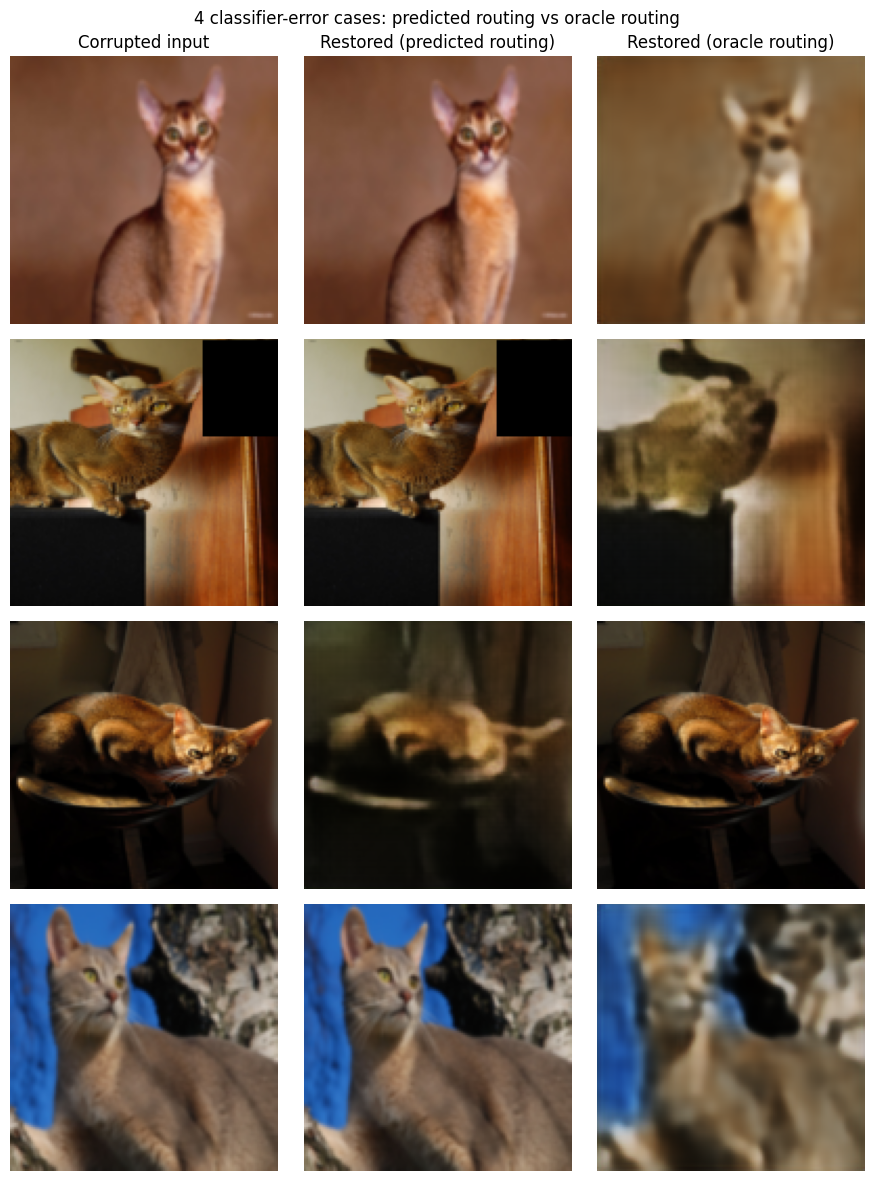

Saved to /content/drive/MyDrive/task2_artifacts_correct/results/misrouting_failure_cases.png


In [ ]:
# ============================================================
# Cases where classifier errors cause restoration failures
# ============================================================

misroute_rate = predicted_df['misrouted'].mean()
print(f'Overall misrouting rate on the test set: {misroute_rate:.2%}')

correctly_routed = predicted_df[~predicted_df['misrouted']]
misrouted = predicted_df[predicted_df['misrouted']]
print(f"\nRestoration quality, correctly-routed vs misrouted samples "
      f"({len(correctly_routed)} vs {len(misrouted)} samples):")
compare_tbl = __import__('pandas').DataFrame({
    'correctly_routed': correctly_routed[['l1', 'ssim', 'psnr']].mean(),
    'misrouted': misrouted[['l1', 'ssim', 'psnr']].mean() if len(misrouted) else float('nan'),
})
print(compare_tbl.to_string())
compare_tbl.to_csv(os.path.join(RESULTS_DIR, 'misrouted_vs_correct_quality.csv'))

# Which TRUE type gets misrouted most often, and to which WRONG expert?
if len(misrouted) > 0:
    misroute_confusion = misrouted.groupby(['ctype'])['pred_label'].apply(
        lambda s: s.map(lambda i: CORRUPTION_TYPES[i]).value_counts().to_dict())
    print('\nWhere misroutes go (true type -> {wrong predicted type: count}):')
    print(misroute_confusion.to_string())


def show_routing_examples(indices, title, save_name, predicted_records_df=None):
    n = len(indices)
    fig, axes = plt.subplots(n, 3, figsize=(9, 3 * n))
    if n == 1:
        axes = axes[None, :]
    col_titles = ['Corrupted input', 'Restored (predicted routing)', 'Restored (oracle routing)']
    with torch.no_grad():
        for row, idx in enumerate(indices):
            sample = test_ds[idx]
            clean = sample['clean'].unsqueeze(0).to(DEVICE)
            corrupted = sample['corrupted'].unsqueeze(0).to(DEVICE)
            true_label = torch.tensor([sample['label']], device=DEVICE)
            pred_label = classifier(corrupted).argmax(1)

            x_hat_pred = hard_route_batch(corrupted, pred_label, specialists)
            x_hat_oracle = hard_route_batch(corrupted, true_label, specialists)

            imgs = [corrupted[0].cpu().permute(1, 2, 0).numpy(),
                    x_hat_pred[0].clamp(0, 1).cpu().permute(1, 2, 0).numpy(),
                    x_hat_oracle[0].clamp(0, 1).cpu().permute(1, 2, 0).numpy()]
            for col, img in enumerate(imgs):
                axes[row, col].imshow(img)
                axes[row, col].axis('off')
                if row == 0:
                    axes[row, col].set_title(col_titles[col])
            true_name = CORRUPTION_TYPES[sample['label']]
            pred_name = CORRUPTION_TYPES[pred_label.item()]
            axes[row, 0].set_ylabel(f'true={true_name}\npred={pred_name}', fontsize=8)
    fig.suptitle(title)
    plt.tight_layout()
    out_path = os.path.join(RESULTS_DIR, save_name)
    plt.savefig(out_path, dpi=120, bbox_inches='tight')
    plt.show()
    print('Saved to', out_path)


misrouted_test_indices = predicted_df.index[predicted_df['misrouted']].tolist()[:4]
if misrouted_test_indices:
    show_routing_examples(misrouted_test_indices,
                           '4 classifier-error cases: predicted routing vs oracle routing',
                           'misrouting_failure_cases.png')
else:
    print('No misrouted samples found in the test set -- classifier was perfect on this run.')


**Discussion of misrouting.** About 1.7% of test inputs are misrouted, and almost all of them are mildly corrupted images sent to the identity bypass. These inputs are already close to the clean target, so misrouted samples still have high SSIM. The harmful case is an occlusion predicted as clean: the black rectangles stay in the output (see the figure above).

## 16b. Comparison with the Task 1 universal autoencoder

        ctype severity  ssim_task1  ssim_oracle  ssim_predicted  psnr_task1  psnr_oracle  psnr_predicted
        clean       na      0.4060       1.0000          0.9977     16.7980      80.0000         79.3514
gaussian_blur     high      0.4050       0.6951          0.6951     16.7858      24.0868         24.0868
gaussian_blur      low      0.4058       0.7209          0.7554     16.7938      24.3759         25.3416
gaussian_blur   medium      0.4055       0.7155          0.7155     16.7901      24.4266         24.4266
    occlusion     high      0.3565       0.6068          0.6073     14.4381      19.9418         19.9351
    occlusion      low      0.3918       0.6882          0.6963     16.1938      22.7174         22.6167
    occlusion   medium      0.3772       0.6542          0.6546     15.4666      21.4717         21.4684
  salt_pepper     high      0.4050       0.6951          0.6951     16.8415      24.0530         24.0530
  salt_pepper      low      0.4060       0.7060        

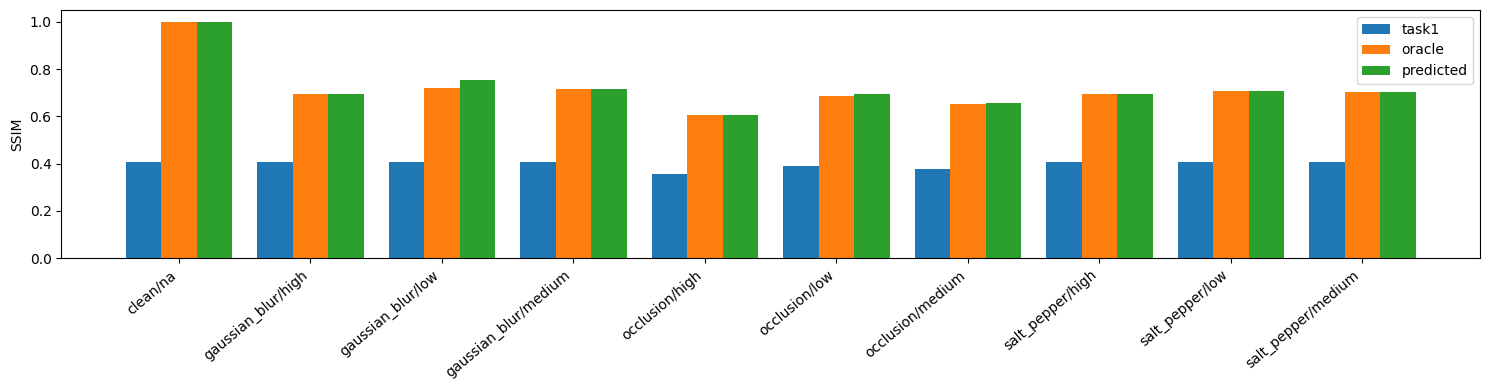

In [ ]:
import pandas as pd
_t1_csv = '/content/drive/MyDrive/universal_restoration/results/test_metrics_by_type_severity.csv'
if os.path.exists(_t1_csv):
    t1 = pd.read_csv(_t1_csv)
    comp = (t1.merge(oracle_summary, on=['ctype', 'severity'], suffixes=('_task1', ''))
              .merge(predicted_summary, on=['ctype', 'severity'], suffixes=('_oracle', '_predicted')))
    cols = ['ctype', 'severity'] + [f'{m}_{s}' for m in ['ssim', 'psnr'] for s in ['task1', 'oracle', 'predicted']]
    print(comp[cols].round(4).to_string(index=False))
    comp.to_csv(os.path.join(RESULTS_DIR, 'task1_vs_task2.csv'), index=False)
    x = np.arange(len(comp)); w = 0.27
    fig, ax = plt.subplots(figsize=(15, 4))
    for k, s in enumerate(['task1', 'oracle', 'predicted']):
        ax.bar(x + (k - 1) * w, comp[f'ssim_{s}'], w, label=s)
    ax.set_xticks(x); ax.set_xticklabels(comp['ctype'] + '/' + comp['severity'], rotation=40, ha='right'); ax.set_ylabel('SSIM'); ax.legend()
    plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, 'task1_vs_task2.png'), dpi=120, bbox_inches='tight'); plt.show()
else:
    print('Task 1 results not found at', _t1_csv)

**When specialists help or fail.** Each specialist learns a single inverse mapping, and clean inputs bypass restoration entirely (SSIM 1.0), so hard routing beats the universal model wherever the classifier is right. It fails when the classifier is wrong, for example an occlusion predicted as clean, and when an image contains a mix of corruptions, because only one expert is ever applied.

## 17. Export to ONNX for the *Hard-Routed Restoration* app workspace
Exports the classifier and all three specialists as separate ONNX graphs, plus `app_config.json` describing how the app should orchestrate routing.

In [ ]:
# ============================================================
# Export the classifier and all three specialists to ONNX for the
# "Hard-Routed Restoration" application workspace. The app orchestrates
# routing itself: run classifier.onnx -> argmax -> dispatch to the
# matching specialist ONNX graph (or identity bypass if predicted clean).
# ============================================================

classifier.eval().cpu()
dummy_img = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)
clf_onnx_path = os.path.join(ONNX_DIR, 'classifier.onnx')
torch.onnx.export(classifier, dummy_img, clf_onnx_path,
                   input_names=['corrupted_image'], output_names=['logits'],
                   dynamic_axes={'corrupted_image': {0: 'batch'}, 'logits': {0: 'batch'}},
                   opset_version=17, dynamo=False)
classifier.to(DEVICE)

import onnx
onnx.checker.check_model(onnx.load(clf_onnx_path))
print('Classifier exported to', clf_onnx_path)

specialist_onnx_paths = {}
for ctype, model in specialists.items():
    model.eval().cpu()
    path = os.path.join(ONNX_DIR, f'specialist_{ctype}.onnx')
    torch.onnx.export(model, dummy_img, path,
                       input_names=['corrupted_image'], output_names=['restored_image'],
                       dynamic_axes={'corrupted_image': {0: 'batch'}, 'restored_image': {0: 'batch'}},
                       opset_version=17, dynamo=False)
    model.to(DEVICE)
    onnx.checker.check_model(onnx.load(path))
    specialist_onnx_paths[ctype] = path
    print(f'Specialist [{ctype}] exported to', path)

# Round-trip sanity check + inference-time measurement with onnxruntime
import onnxruntime as ort

clf_sess = ort.InferenceSession(clf_onnx_path, providers=['CPUExecutionProvider'])
t0 = time.time()
logits = clf_sess.run(None, {'corrupted_image': dummy_img.numpy()})[0]
clf_time_ms = (time.time() - t0) * 1000
print(f'\nClassifier ONNX Runtime check OK, logits shape {logits.shape}, inference time {clf_time_ms:.1f} ms')

specialist_times = {}
for ctype, path in specialist_onnx_paths.items():
    sess = ort.InferenceSession(path, providers=['CPUExecutionProvider'])
    t0 = time.time()
    out = sess.run(None, {'corrupted_image': dummy_img.numpy()})[0]
    dt = (time.time() - t0) * 1000
    specialist_times[ctype] = dt
    print(f'Specialist [{ctype}] ONNX Runtime check OK, output shape {out.shape}, inference time {dt:.1f} ms')

with open(os.path.join(ONNX_DIR, 'app_config.json'), 'w') as f:
    json.dump({
        'img_size': IMG_SIZE,
        'input_range': '[0,1] float32, CHW, RGB',
        'class_names': CORRUPTION_TYPES,
        'routing_rule': 'classifier argmax selects the expert; class 0 (clean) is an identity bypass',
        'classifier_config': clf_ckpt['config'],
        'specialist_configs': {ctype: specialists[ctype].encoder.stem[0].in_channels and
                                {'base_channels': spec_base_channels, 'bottleneck_channels': spec_bottleneck_channels,
                                 'dropout': spec_dropout, 'n_res_blocks': spec_n_res_blocks}
                                for ctype in specialists},
        'onnx_files': {'classifier': 'classifier.onnx',
                        **{f'specialist_{k}': f'specialist_{k}.onnx' for k in specialists}},
        'approx_inference_time_ms_cpu': {'classifier': clf_time_ms, **specialist_times},
    }, f, indent=2)

print('\nAll models exported. app_config.json written for the Hard-Routed Restoration workspace.')

# Verify ONNX Runtime outputs against PyTorch on real test images
_x = torch.stack([test_ds[i]['corrupted'] for i in range(0, 640, 20)])
with torch.no_grad():
    _pt = classifier.cpu().eval()(_x).numpy()
_ox = clf_sess.run(None, {'corrupted_image': _x.numpy()})[0]
print(f'classifier: max |diff| = {np.abs(_pt - _ox).max():.2e}, same argmax: {(_pt.argmax(1) == _ox.argmax(1)).mean():.0%}')
classifier.to(DEVICE)
for ctype, path in specialist_onnx_paths.items():
    with torch.no_grad():
        _pt = specialists[ctype].cpu().eval()(_x).numpy()
    _ox = ort.InferenceSession(path, providers=['CPUExecutionProvider']).run(None, {'corrupted_image': _x.numpy()})[0]
    print(f'specialist_{ctype}: max |diff| = {np.abs(_pt - _ox).max():.2e}, mean |diff| = {np.abs(_pt - _ox).mean():.2e}')
    specialists[ctype].to(DEVICE)

/tmp/ipykernel_918/244496085.py:11: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(classifier, dummy_img, clf_onnx_path,


Classifier exported to /content/drive/MyDrive/task2_artifacts_correct/onnx_export/classifier.onnx


/tmp/ipykernel_918/244496085.py:25: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model, dummy_img, path,


Specialist [salt_pepper] exported to /content/drive/MyDrive/task2_artifacts_correct/onnx_export/specialist_salt_pepper.onnx
Specialist [gaussian_blur] exported to /content/drive/MyDrive/task2_artifacts_correct/onnx_export/specialist_gaussian_blur.onnx
Specialist [occlusion] exported to /content/drive/MyDrive/task2_artifacts_correct/onnx_export/specialist_occlusion.onnx

Classifier ONNX Runtime check OK, logits shape (1, 4), inference time 9.4 ms
Specialist [salt_pepper] ONNX Runtime check OK, output shape (1, 3, 128, 128), inference time 46.8 ms
Specialist [gaussian_blur] ONNX Runtime check OK, output shape (1, 3, 128, 128), inference time 70.0 ms
Specialist [occlusion] ONNX Runtime check OK, output shape (1, 3, 128, 128), inference time 60.2 ms

All models exported. app_config.json written for the Hard-Routed Restoration workspace.
classifier: max |diff| = 8.11e-06, same argmax: 100%
specialist_salt_pepper: max |diff| = 2.62e-05, mean |diff| = 1.66e-07
specialist_gaussian_blur: max |d

## 18. Final test: reload everything from Drive and run the full architecture
This is the definitive end-to-end check — fresh model instances, loaded strictly from their saved Drive checkpoints (not whatever's currently in memory), run through the complete classify → route → restore pipeline. For each example: the clean target, the corrupted input, the classifier's verdict (all 4 probabilities, predicted class, whether it was correct, which expert was selected, inference time), and the restored output. Finishes with one more oracle-vs-predicted quantitative pass on the full test set using these freshly-loaded models, as final confirmation that what's saved on Drive actually works standalone.

Reloading classifier + specialists from Drive checkpoints...
Classifier loaded from /content/drive/MyDrive/task2_artifacts_correct/checkpoints/classifier_best.pt (val_loss=0.0461)
Specialist [salt_pepper] loaded from /content/drive/MyDrive/task2_artifacts_correct/checkpoints/specialist_salt_pepper_best.pt (val_loss=0.0570)
Specialist [gaussian_blur] loaded from /content/drive/MyDrive/task2_artifacts_correct/checkpoints/specialist_gaussian_blur_best.pt (val_loss=0.0991)
Specialist [occlusion] loaded from /content/drive/MyDrive/task2_artifacts_correct/checkpoints/specialist_occlusion_best.pt (val_loss=0.3225)

All 4 models loaded fresh from Drive. Nothing below depends on training having just run in this session -- re-running only this cell (after the setup cells) is enough to test the full system.


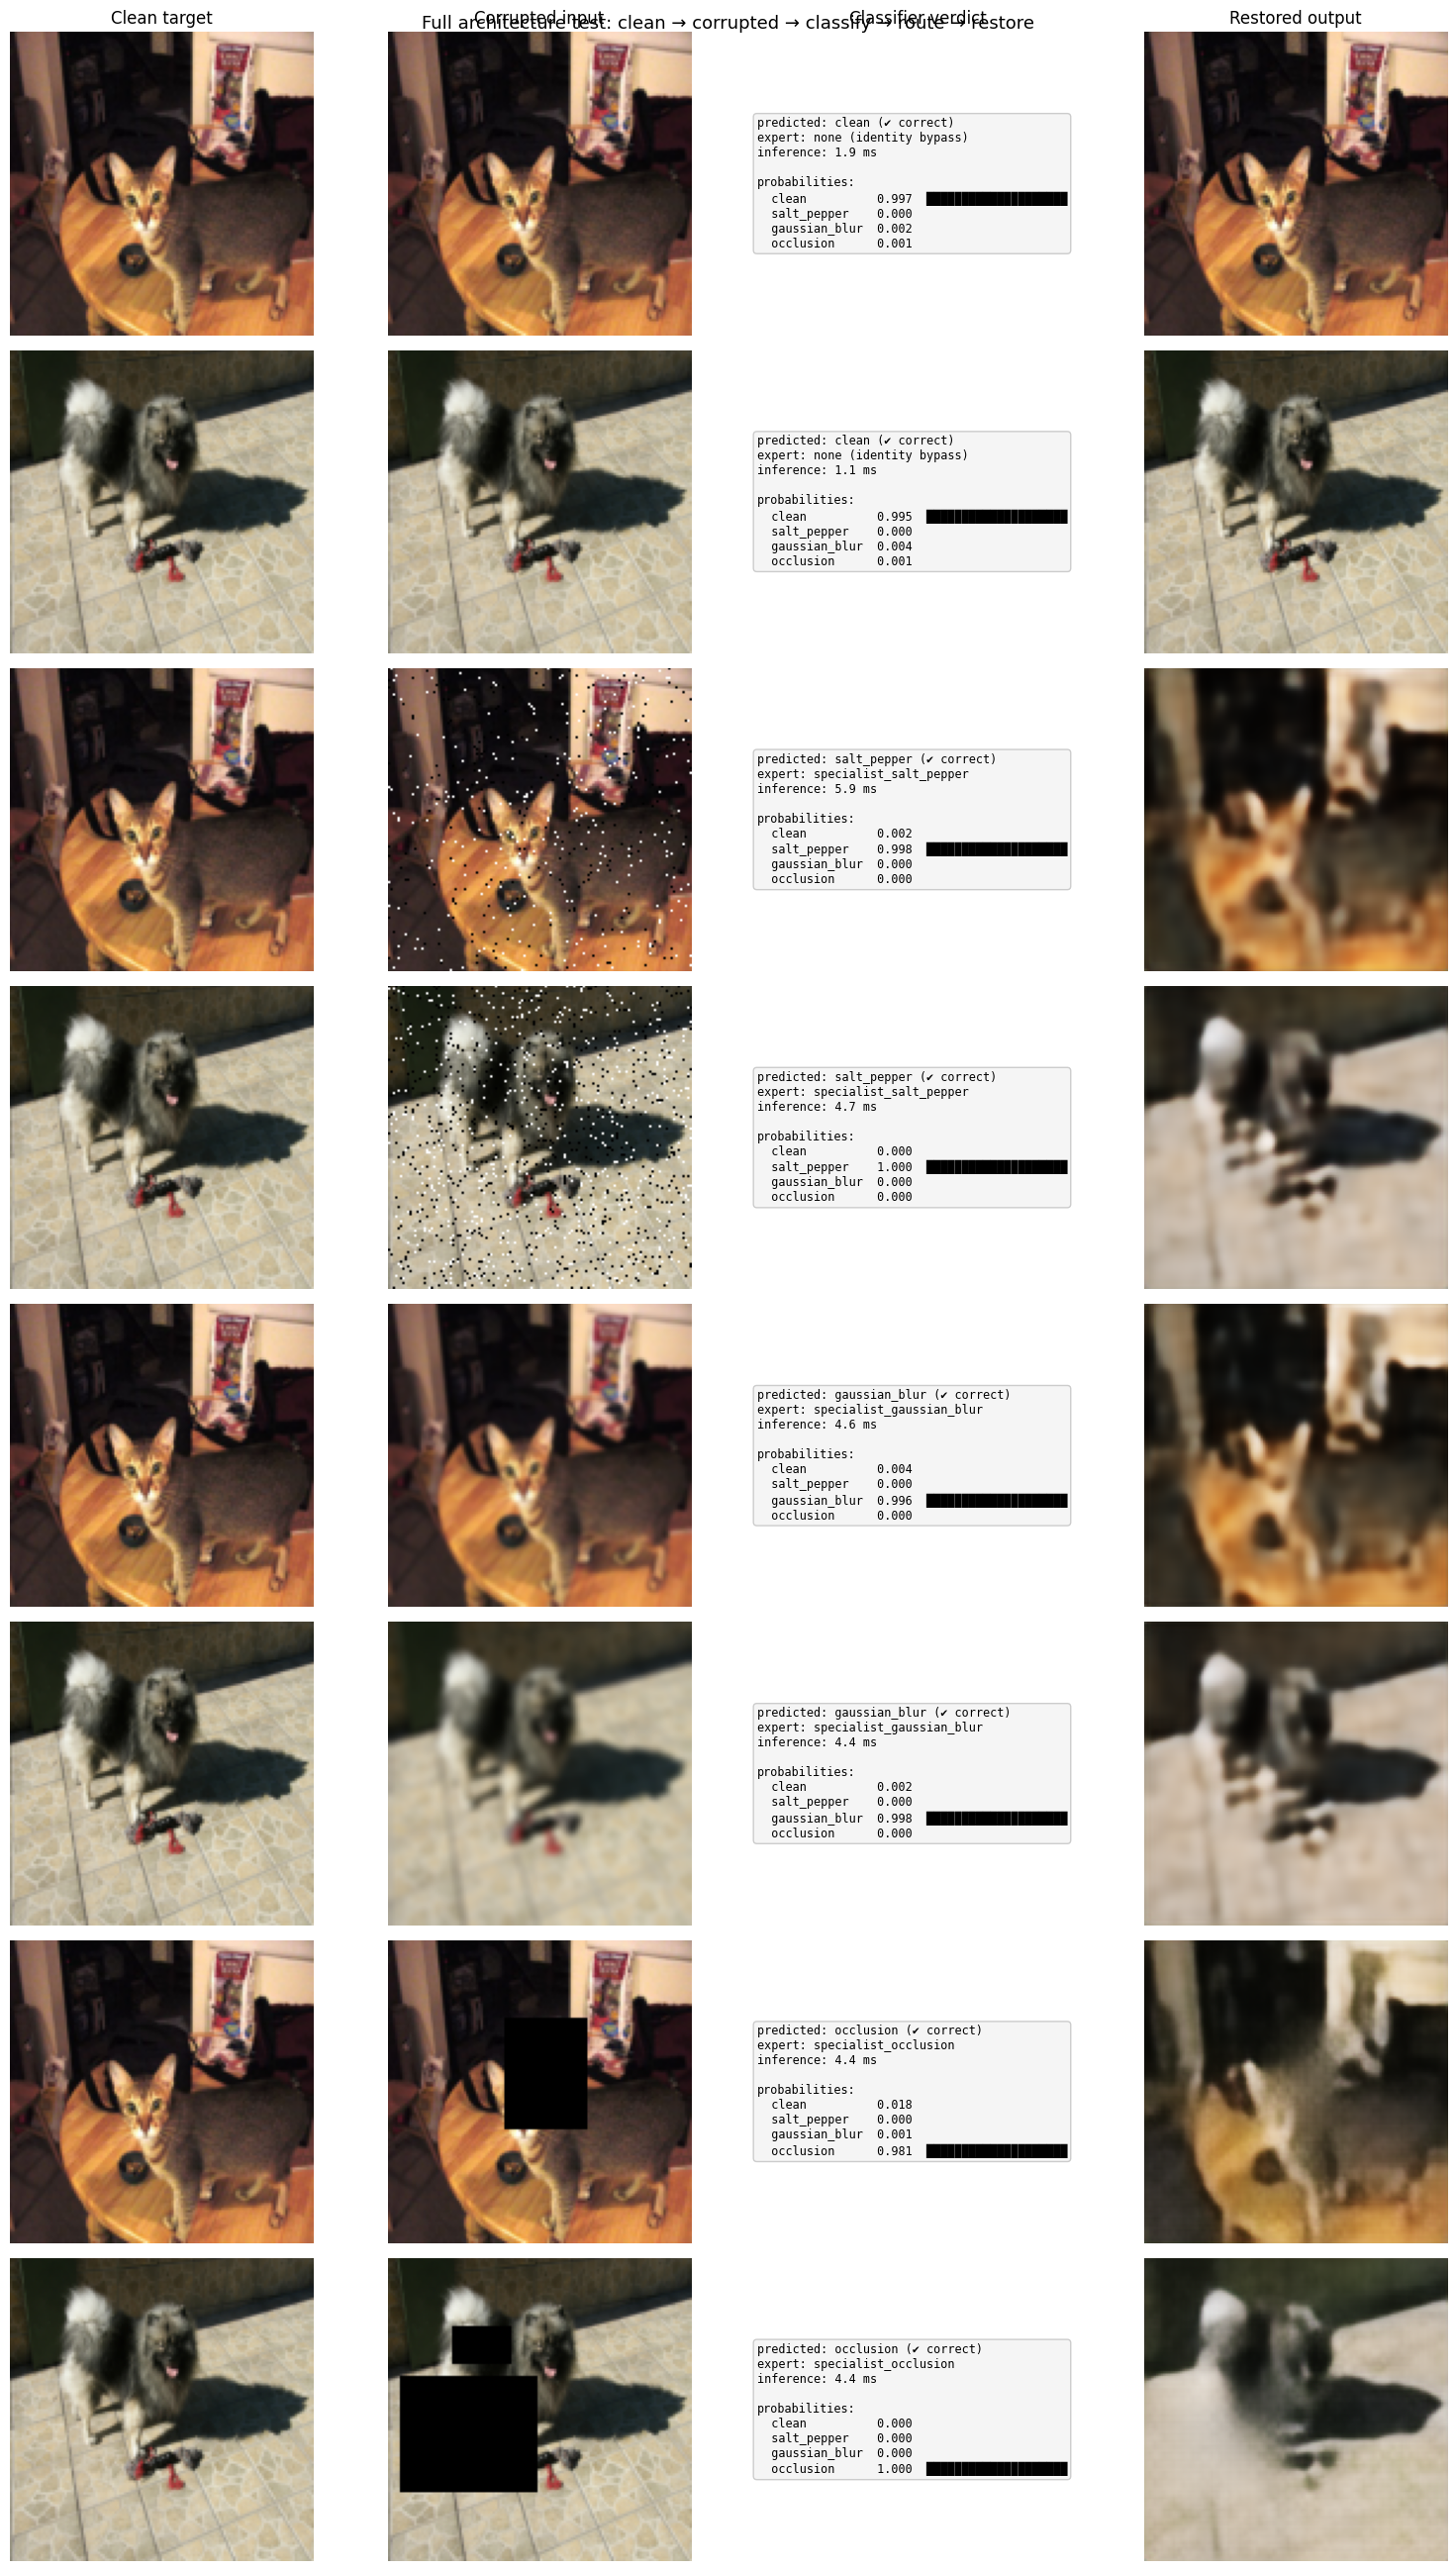

Saved to /content/drive/MyDrive/task2_artifacts_correct/results/final_architecture_test.png

Final quantitative check (freshly loaded models, full test set)

Oracle routing (specialist ceiling):
        ctype severity       l1     ssim      psnr
        clean       na 0.000000 1.000000 80.000000
gaussian_blur     high 0.046083 0.695147 24.086771
gaussian_blur      low 0.044594 0.720876 24.375940
gaussian_blur   medium 0.044453 0.715518 24.426598
    occlusion     high 0.066916 0.606808 19.941774
    occlusion      low 0.051357 0.688178 22.717377
    occlusion   medium 0.057190 0.654246 21.471681
  salt_pepper     high 0.046070 0.695065 24.053030
  salt_pepper      low 0.045024 0.705971 24.244166
  salt_pepper   medium 0.045233 0.702498 24.204045

Predicted routing (full operational system):
        ctype severity       l1     ssim      psnr
        clean       na 0.000402 0.997695 79.351422
gaussian_blur     high 0.046083 0.695147 24.086771
gaussian_blur      low 0.040356 0.755408 25.3

In [ ]:
# ============================================================
# FINAL TEST: reload the classifier and all 3 specialists strictly from
# their saved Drive checkpoints (fresh model instances, not whatever
# happens to be in memory from earlier in this session) and run the
# complete hard-routed pipeline end to end. This is the "does this
# actually work from scratch, the way a fresh Colab session would load
# it" test -- and it doubles as the Hard-Routed Restoration app's display:
# corrupted input, the 4 classifier probabilities, predicted corruption,
# selected expert, reconstructed image, and inference time.
# ============================================================

print('=' * 70)
print('Reloading classifier + specialists from Drive checkpoints...')
print('=' * 70)

_clf_path = find_file('classifier_best.pt')
assert _clf_path is not None, 'classifier_best.pt not found on Drive -- train the classifier first.'
_clf_ckpt = torch.load(_clf_path, map_location=DEVICE)
loaded_classifier = CorruptionClassifier(**_clf_ckpt['config']).to(DEVICE)
loaded_classifier.load_state_dict(_clf_ckpt['model_state'])
loaded_classifier.eval()
print(f'Classifier loaded from {_clf_path} (val_loss={_clf_ckpt["val_loss"]:.4f})')

loaded_specialists = {}
for ctype in ['salt_pepper', 'gaussian_blur', 'occlusion']:
    _path = find_file(f'specialist_{ctype}_best.pt')
    assert _path is not None, f'specialist_{ctype}_best.pt not found on Drive -- train it first.'
    _ckpt = torch.load(_path, map_location=DEVICE)
    model = SpecialistAutoencoder(**_ckpt['config']).to(DEVICE)
    model.load_state_dict(_ckpt['model_state'])
    model.eval()
    loaded_specialists[ctype] = model
    print(f'Specialist [{ctype}] loaded from {_path} (val_loss={_ckpt["val_loss"]:.4f})')

print('\nAll 4 models loaded fresh from Drive. Nothing below depends on training having just run '
      'in this session -- re-running only this cell (after the setup cells) is enough to test the '
      'full system.')


@torch.no_grad()
def run_full_pipeline(clean, corrupted, classifier, specialists, device):
    """The exact hard-routed inference path: classify, then dispatch to
    the matching specialist, or bypass (identity) if predicted clean.
    Returns the restored image, the 4 class probabilities, the predicted
    class name, the selected expert name, and inference time in ms."""
    t0 = time.time()
    logits = classifier(corrupted)
    probs = F.softmax(logits, dim=1).squeeze(0).cpu().numpy()
    pred_idx = int(probs.argmax())
    pred_name = CORRUPTION_TYPES[pred_idx]

    if pred_name == 'clean':
        restored = corrupted.clone()
        expert_used = 'none (identity bypass)'
    else:
        restored = specialists[pred_name](corrupted)
        expert_used = f'specialist_{pred_name}'
    inference_ms = (time.time() - t0) * 1000
    return restored, probs, pred_name, expert_used, inference_ms


def show_full_architecture_test(ds, n_per_class=2, save_name='final_architecture_test.png'):
    rows = []
    for ctype in CORRUPTION_TYPES:
        matching = [i for i, e in enumerate(ds.manifest) if e['ctype'] == ctype]
        if not matching:
            continue
        chosen = matching[::max(1, len(matching) // n_per_class)][:n_per_class]
        rows.extend(chosen)

    n = len(rows)
    fig, axes = plt.subplots(n, 4, figsize=(15, 3.3 * n))
    if n == 1:
        axes = axes[None, :]
    col_titles = ['Clean target', 'Corrupted input', 'Classifier verdict', 'Restored output']

    for row, idx in enumerate(rows):
        sample = ds[idx]
        clean = sample['clean'].unsqueeze(0).to(DEVICE)
        corrupted = sample['corrupted'].unsqueeze(0).to(DEVICE)
        true_name = CORRUPTION_TYPES[sample['label']]

        restored, probs, pred_name, expert_used, inference_ms = run_full_pipeline(
            clean, corrupted, loaded_classifier, loaded_specialists, DEVICE)

        axes[row, 0].imshow(clean[0].cpu().permute(1, 2, 0).numpy())
        axes[row, 0].axis('off')
        axes[row, 0].set_ylabel(f'true={true_name}', fontsize=9)
        if row == 0:
            axes[row, 0].set_title(col_titles[0])

        axes[row, 1].imshow(corrupted[0].cpu().permute(1, 2, 0).numpy())
        axes[row, 1].axis('off')
        if row == 0:
            axes[row, 1].set_title(col_titles[1])

        axes[row, 2].axis('off')
        if row == 0:
            axes[row, 2].set_title(col_titles[2])
        correct = '✔ correct' if pred_name == true_name else '✘ WRONG'
        lines = [f'predicted: {pred_name} ({correct})', f'expert: {expert_used}',
                 f'inference: {inference_ms:.1f} ms', '', 'probabilities:']
        for cname, p in zip(CORRUPTION_TYPES, probs):
            bar = '█' * int(round(p * 20))
            lines.append(f'  {cname:<14s} {p:5.3f}  {bar}')
        axes[row, 2].text(0.0, 0.5, '\n'.join(lines), fontsize=8.5, family='monospace',
                           va='center', ha='left', transform=axes[row, 2].transAxes,
                           bbox=dict(boxstyle='round', facecolor='#f5f5f5', edgecolor='#cccccc'))

        axes[row, 3].imshow(restored[0].clamp(0, 1).cpu().permute(1, 2, 0).numpy())
        axes[row, 3].axis('off')
        if row == 0:
            axes[row, 3].set_title(col_titles[3])

    fig.suptitle('Full architecture test: clean \u2192 corrupted \u2192 classify \u2192 route \u2192 restore', fontsize=13)
    plt.tight_layout()
    out_path = os.path.join(RESULTS_DIR, save_name)
    plt.savefig(out_path, dpi=120, bbox_inches='tight')
    plt.show()
    print('Saved to', out_path)


show_full_architecture_test(test_ds, n_per_class=2)

# ---- final quantitative check: oracle vs predicted routing, using the
# freshly Drive-loaded models, on the FULL test set ----
print('\n' + '=' * 70)
print('Final quantitative check (freshly loaded models, full test set)')
print('=' * 70)
_final_test_loader = make_loader(test_ds, batch_size=64, shuffle=False, drop_last=False)
_oracle_records = evaluate_hard_routing(loaded_classifier, loaded_specialists, _final_test_loader, DEVICE, mode='oracle')
_predicted_records = evaluate_hard_routing(loaded_classifier, loaded_specialists, _final_test_loader, DEVICE, mode='predicted')
_, _oracle_summary = summarize_breakdown(_oracle_records)
_, _predicted_summary = summarize_breakdown(_predicted_records)
print('\nOracle routing (specialist ceiling):')
print(_oracle_summary.to_string(index=False))
print('\nPredicted routing (full operational system):')
print(_predicted_summary.to_string(index=False))


## Experiment tracking (MLflow)

In [ ]:
# Log classifier, specialists and routing results to MLflow (store kept on Drive)
import mlflow, glob
MLFLOW_DIR = '/content/drive/MyDrive/mlflow_genai'
os.makedirs(MLFLOW_DIR, exist_ok=True)
mlflow.set_tracking_uri(f'sqlite:///{MLFLOW_DIR}/mlflow.db')
EXP = 'Task2-Hard-Routing'
if mlflow.get_experiment_by_name(EXP) is None:
    mlflow.create_experiment(EXP, artifact_location=os.path.join(MLFLOW_DIR, 'artifacts', EXP))
_exp = mlflow.set_experiment(EXP)

def _new_run(name):
    return not len(mlflow.search_runs([_exp.experiment_id], filter_string=f"tags.mlflow.runName = '{name}'"))

def _log_history(hist):
    for rec in hist or []:
        mlflow.log_metrics({k: float(v) for k, v in rec.items() if k != 'epoch'}, step=int(rec['epoch']))

def _log_optuna(json_path):
    if os.path.exists(json_path):
        for t in json.load(open(json_path)):
            with mlflow.start_run(run_name=f"optuna_trial_{t['number']}", nested=True):
                mlflow.log_params(t['params']); mlflow.set_tag('state', t['state'])
                if t['value'] is not None:
                    mlflow.log_metric('objective', t['value'])

if _new_run('classifier'):
    with mlflow.start_run(run_name='classifier'):
        mlflow.log_params({**CLF_BEST_PARAMS, 'max_epochs': CLF_FINAL_EPOCHS, 'loss': 'cross_entropy'})
        _log_history(clf_history)
        mlflow.log_metrics({k: metrics[k] for k in ['accuracy', 'macro_precision', 'macro_recall', 'macro_f1']})
        for c, m in metrics['per_class'].items():
            mlflow.log_metrics({f'{c}_{k}': v for k, v in m.items() if k != 'support'})
        _log_optuna(os.path.join(RESULTS_DIR, 'classifier_optuna_all_trials.json'))
        mlflow.log_artifact(find_file('classifier_best.pt'), 'checkpoint')
        mlflow.log_artifact(os.path.join(ONNX_DIR, 'classifier.onnx'), 'onnx')
for ctype in ['salt_pepper', 'gaussian_blur', 'occlusion']:
    if _new_run(f'specialist_{ctype}'):
        with mlflow.start_run(run_name=f'specialist_{ctype}'):
            mlflow.log_params({**SPEC_BEST_PARAMS, 'corruption': ctype, 'max_epochs': SPEC_FINAL_EPOCHS})
            _log_history(specialist_histories.get(ctype))
            for _, r in oracle_summary[oracle_summary['ctype'] == ctype].iterrows():
                mlflow.log_metrics({f"test_{r['severity']}_{m}": float(r[m]) for m in ['l1', 'ssim', 'psnr']})
            mlflow.log_artifact(find_file(f'specialist_{ctype}_best.pt'), 'checkpoint')
            mlflow.log_artifact(os.path.join(ONNX_DIR, f'specialist_{ctype}.onnx'), 'onnx')
            for f in sorted(glob.glob(os.path.join(RESULTS_DIR, 'snapshots', f'{ctype}_epoch*.png'))):
                mlflow.log_artifact(f, 'snapshots')
if _new_run('hard_routing'):
    with mlflow.start_run(run_name='hard_routing'):
        for name, df in [('oracle', oracle_summary), ('predicted', predicted_summary)]:
            for _, r in df.iterrows():
                mlflow.log_metrics({f"{name}_{r['ctype']}_{r['severity']}_{m}": float(r[m]) for m in ['l1', 'ssim', 'psnr']})
        mlflow.log_metric('misroute_rate', float(predicted_df['misrouted'].mean()))
        _log_optuna(os.path.join(RESULTS_DIR, 'specialist_optuna_all_trials.json'))
        for f in glob.glob(os.path.join(RESULTS_DIR, '*.png')) + glob.glob(os.path.join(RESULTS_DIR, '*.csv')) + glob.glob(os.path.join(RESULTS_DIR, '*.json')):
            mlflow.log_artifact(f, 'results')
print('Logged to MLflow:', mlflow.get_tracking_uri())

Logged to MLflow: sqlite:////content/drive/MyDrive/mlflow_genai/mlflow.db
